# Experiment B &mdash; Prior-Guided Bayesian Optimization

Comparison of four ways of injecting a Gaussian domain prior
$\pi_c(x) = \exp\!\big(-\Vert x - c\Vert^2 / (2\ell^2)\big) \in [0,1]$ into GP-BO
on a benchmark kept on its **raw (natural) scale**, only oriented to a
maximization problem ($g = -f_\mathrm{raw}$ for a minimization benchmark; oracle
$f(x^\star) = f_\mathrm{opt} = \max_x g(x)$, **not** rescaled to $[0,1]$):

| method | GP | prior enters |
|---|---|---|
| `vanilla_ucb` | generic | nowhere (baseline) |
| `alpha_pi_ucb` | generic | acquisition only: $a(x) = \mu(x) + w(x)\sqrt{\beta}\,\sigma(x)$, $w = (1-\alpha) + \alpha\pi$ (weight $\pi\in[0,1]$) |
| `lambda_pi_fixed_ucb` | prior mean $1\cdot f_\mathrm{prior}$ | GP mean, $\lambda = 1$ fixed |
| `lambda_pi_adaptive_ucb` | prior mean $\hat\lambda\,f_\mathrm{prior}$ | GP mean, $\lambda$ learned by MLL |

Three distinct objects are kept separate: the spatial weight $\pi(x)\in[0,1]$
(acquisition), the prior **mean** $f_\mathrm{prior}(x) = \mathrm{baseline} +
\mathrm{amplitude}\cdot\pi(x)$ on the $y$ scale (used only by the
prior-to-the-mean methods), and the raw objective $f(x)$ (observations and
regret).

The notebook is **generic and dimension-aware**: it reads everything from one run
directory (`config.json`, raw seeds, processed per-seed files, aggregates) and
selects the visualization strategy from the benchmark dimension
($d=1$ &rarr; full curves, $d=2$ &rarr; spatial maps, $d>2$ &rarr; line slices +
distance diagnostics).  Changing the run directory is sufficient; no plotting
cell needs to be rewritten.


## 0. Configuration and result loading
### 0.1 Imports and plotting style

In [509]:
from __future__ import annotations

import json
import math
import os
import sys
from pathlib import Path
from typing import Any, Optional

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Locate the repository root by walking up until common/priors.py is found,
# so the notebook works from notebooks/ or from the repo root.
_p = Path.cwd().resolve()
while not (_p / "common" / "priors.py").exists():
    if _p.parent == _p:
        raise RuntimeError("Could not locate the repository root from " + str(Path.cwd()))
    _p = _p.parent
REPO_ROOT = _p
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

from common.serialization import load_json                          # noqa: E402
from common.priors import GaussianPrior, PriorMeanModule            # noqa: E402
from benchmarks.oriented import build_oriented_benchmark            # noqa: E402
from data.raw_prior import RawPriorSeedData                         # noqa: E402
from data.processed_prior import ProcessedPriorSeedData             # noqa: E402
from experiments.exp_b_prior_guided.run import (                    # noqa: E402
    _METHOD_SPECS, make_model_builder,
)
from experiments.exp_b_prior_guided.process import (                # noqa: E402
    _reconstruction_config, _reconstruct_X_Y, _rebuild_gp_at_snapshot,
)
from acquisitions.prior_guided import VanillaUCB                    # noqa: E402

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "axes.grid": True,
    "grid.alpha": 0.3,
})

# Canonical colours / labels (consistent across every figure).
METHOD_STYLE = {
    "vanilla_ucb":            {"label": "vanilla UCB",            "color": "#4D4D4D"},
    "alpha_pi_ucb":           {"label": r"$\alpha\pi$-UCB (SoC)",  "color": "#0072B2"},
    "lambda_pi_fixed_ucb":    {"label": r"$\lambda\pi$ fixed",     "color": "#E69F00"},
    "lambda_pi_adaptive_ucb": {"label": r"$\lambda\pi$ adaptive",  "color": "#D55E00"},
    "lambda_pi_fixed_standardized_ucb":    {"label": r"$\lambda\pi$ fixed (std)",    "color": "#CC79A7"},
    "lambda_pi_adaptive_standardized_ucb": {"label": r"$\lambda\pi$ adaptive (std)", "color": "#009E73"},
}
def style_for(method: str) -> dict:
    return METHOD_STYLE.get(method, {"label": method, "color": None})

# Global figure registry: every plotting cell does add_figure("<name>", fig).
FIGURES: dict[str, plt.Figure] = {}
def add_figure(name: str, fig: plt.Figure) -> plt.Figure:
    if name in FIGURES:
        print(f"[warn] overwriting already-registered figure '{name}'")
    FIGURES[name] = fig
    return fig

DEVICE = torch.device("cpu")
torch.set_default_dtype(torch.double)


In [510]:
# ---------------------------------------------------------------------------
# Centralized figure style — publication / lab-presentation look.
#
# Backend precedence: scienceplots -> seaborn -> hand-built matplotlib theme.
# Whichever loads, the rcParams block below is applied on top so the final
# look is identical and reproducible.  `text.usetex` is forced OFF, so PDF/PNG
# export never depends on a LaTeX installation (math is rendered via mathtext).
# Nothing here changes any plotted DATA — only fonts, colours, line widths,
# grids, backgrounds and legends.
# ---------------------------------------------------------------------------
import warnings
import matplotlib as mpl

_STYLE_BACKEND = "matplotlib-fallback"
try:
    import scienceplots  # noqa: F401  (registers the 'science' style sheets)
    plt.style.use(["science", "grid", "no-latex"])
    _STYLE_BACKEND = "scienceplots"
except Exception:
    try:
        import seaborn as sns
        sns.set_theme(context="notebook", style="whitegrid",
                      palette="colorblind", font_scale=1.0)
        _STYLE_BACKEND = "seaborn"
    except Exception:
        pass

mpl.rcParams.update({
    "text.usetex": False,
    "mathtext.fontset": "cm",
    "figure.dpi": 120, "savefig.dpi": 300,
    "savefig.bbox": "tight", "savefig.transparent": False,
    "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
    "xtick.labelsize": 9.5, "ytick.labelsize": 9.5, "legend.fontsize": 9,
    "axes.titleweight": "semibold",
    "axes.linewidth": 0.9, "axes.edgecolor": "#333333",
    "lines.linewidth": 2.0, "lines.markersize": 6,
    "axes.grid": True, "grid.color": "#B0B0B0",
    "grid.linewidth": 0.6, "grid.alpha": 0.35, "axes.axisbelow": True,
    "legend.frameon": True, "legend.framealpha": 0.9,
    "legend.edgecolor": "#CCCCCC", "legend.fancybox": False,
})

# Colour-blind-safe (Okabe-Ito) cycle, reused as the default property cycle so
# any plot that does NOT pull from METHOD_STYLE still gets accessible colours.
COLORBLIND_CYCLE = ["#0072B2", "#E69F00", "#009E73", "#D55E00",
                    "#CC79A7", "#56B4E9", "#F0E442", "#000000"]
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=COLORBLIND_CYCLE)


def seed_band(ax, x, Y, *, color, label=None, pct=(25, 75),
              show_seeds=False, show_mean=False, lw=2.2, alpha_band=0.15):
    """Median curve + inter-seed percentile band (NaN-robust).

    ``Y`` has shape ``(n_seeds, n_x)``.  Draws the median as a solid line and a
    shaded ``pct`` band; optionally faint per-seed lines and a dashed mean.
    Returns the median ``Line2D``.  Used by the regret-style diagnostics so
    every curve shares one visual language.
    """
    Y = np.asarray(Y, dtype=float)
    med = np.nanmedian(Y, axis=0)
    lo = np.nanpercentile(Y, pct[0], axis=0)
    hi = np.nanpercentile(Y, pct[1], axis=0)
    if show_seeds:
        for row in Y:
            ax.plot(x, row, color=color, lw=0.6, alpha=0.18, zorder=1)
    ax.fill_between(x, lo, hi, color=color, alpha=alpha_band, lw=0, zorder=2)
    line, = ax.plot(x, med, color=color, lw=lw, label=label, zorder=3)
    if show_mean:
        ax.plot(x, np.nanmean(Y, axis=0), color=color, lw=1.3, ls="--",
                alpha=0.9, zorder=3)
    return line


def legend_outside(ax, **kw):
    """Place the legend just outside the right edge (for crowded panels)."""
    return ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5),
                     borderaxespad=0.0, **kw)


print(f"[style] backend = {_STYLE_BACKEND}  (usetex off, mathtext='cm', "
      f"colour-blind palette active)")


[style] backend = scienceplots  (usetex off, mathtext='cm', colour-blind palette active)


### 0.2 Run directory selection

Set `RUN_DIR_OVERRIDE` (or the environment variable `EXP_B_RUN_DIR`) to analyze a
specific run; otherwise the most recent run under
`results/exp_b_prior_guided/runs/` is used.


In [511]:
RUN_DIR_OVERRIDE: Optional[str] = "results/exp_b_prior_guided/runs"   # e.g. "results/exp_b_prior_guided/runs/<run_id>"
EXP_B_RUN_DIR = "2026-07-02_15-25-55_hartmann_6d_good_prior"
_runs_root = REPO_ROOT / "results" / "exp_b_prior_guided" / "runs"
if os.environ.get("EXP_B_RUN_DIR"):
    RUN_DIR = Path(os.environ["EXP_B_RUN_DIR"]).resolve()
elif RUN_DIR_OVERRIDE:
    RUN_DIR = (REPO_ROOT / RUN_DIR_OVERRIDE / EXP_B_RUN_DIR).resolve()
else:
    # Default: the most recent run that has a config.json.
    _candidates = sorted(d for d in _runs_root.iterdir() if (d / "config.json").exists())
    if not _candidates:
        raise FileNotFoundError(f"No runs under {_runs_root}")
    RUN_DIR = _candidates[-1]

# Guard against stale references: every figure in this notebook must come
# from THIS run directory.  A deleted/renamed run fails loudly here instead
# of silently mixing artifacts from different runs or benchmark geometries.
if not (RUN_DIR / "config.json").exists():
    _available = "\n  ".join(d.name for d in sorted(_runs_root.iterdir()))
    raise FileNotFoundError(
        f"RUN_DIR is not a valid run directory: {RUN_DIR}\n"
        f"Available runs:\n  {_available}"
    )
print("RUN_DIR =", RUN_DIR)

RUN_DIR = /users/eleves-b/2023/benjamin.wilhelm/gpbo-separation-of-concerns/bayesian-optimization-separation-concerns/results/exp_b_prior_guided/runs/2026-07-02_15-25-55_hartmann_6d_good_prior


### 0.3 Load config, metadata, processed seeds and aggregates

In [512]:
config = load_json(RUN_DIR / "config.json")
metadata = load_json(RUN_DIR / "metadata.json")

# --- raw seed files (lazy cache; full state dicts live here) ---------------
_raw_root = RUN_DIR / "raw"
# Benchmark name deduced from the config, falling back to the raw/ directory
# (guards against a stale hardcoded BENCH_NAME or a different run's benchmark).
_cfg_bench = config.get("benchmark")
BENCH_NAME_CONFIG = _cfg_bench["name"] if isinstance(_cfg_bench, dict) else _cfg_bench
_raw_dirs = [d.name for d in sorted(_raw_root.iterdir()) if d.is_dir()]
BENCH_NAME = BENCH_NAME_CONFIG if BENCH_NAME_CONFIG in _raw_dirs else _raw_dirs[0]
_raw_files = sorted((_raw_root / BENCH_NAME).glob("seed_*.json"))
SEEDS = [int(p.stem.split("_")[1]) for p in _raw_files]

_RAW_CACHE: dict[int, RawPriorSeedData] = {}
def load_raw(seed: int) -> RawPriorSeedData:
    if seed not in _RAW_CACHE:
        _RAW_CACHE[seed] = RawPriorSeedData.from_dict(
            load_json(_raw_root / BENCH_NAME / f"seed_{seed:03d}.json"))
    return _RAW_CACHE[seed]

raw0 = load_raw(SEEDS[4])

# --- processed per-seed files ----------------------------------------------
_per_seed_dir = RUN_DIR / "processed" / "per_seed" / BENCH_NAME
PROCESSED = [ProcessedPriorSeedData.from_dict(load_json(p))
             for p in sorted(_per_seed_dir.glob("seed_*_processed.json"))]

# --- aggregates --------------------------------------------------------------
_agg_dir = RUN_DIR / "processed" / "aggregate" / BENCH_NAME
def _maybe_load(name: str):
    p = _agg_dir / name
    return load_json(p) if p.exists() else None
AGG = {
    "final":       _maybe_load("final_performance.json"),
    "convergence": _maybe_load("convergence_curves.json"),
    "calib_sum":   _maybe_load("calibration_summary.json"),
    "calib_curves": _maybe_load("calibration_curves.json"),
    "tests":       _maybe_load("statistical_tests.json"),
}

# --- problem & prior reconstruction (bounds / noise / normalization as run) --
problem = build_oriented_benchmark(_reconstruction_config(config, raw0))
prior = GaussianPrior.from_config(raw0.metadata.prior, dim=problem.dim)

DIM      = problem.dim
BUDGET   = raw0.metadata.budget
N_INIT   = raw0.metadata.initial_design_size
N_EVAL   = N_INIT + BUDGET
ALPHA    = float(raw0.metadata.alpha if raw0.metadata.alpha is not None else config.get("alpha", 0.5))
BETA     = float(raw0.metadata.beta  if raw0.metadata.beta  is not None else config["beta"])
F_OPT    = float(raw0.metadata.f_opt)
EPSILON  = PROCESSED[0].epsilon if PROCESSED else config.get("epsilon")
PRIOR_LABEL = (raw0.metadata.prior or {}).get("label", "?")
PI_THRESHOLD = (config.get("calibration", {}) or {}).get("prior_region_threshold", 0.5)

METHODS = [m for m in METHOD_STYLE if m in raw0.methods] + \
          [m for m in raw0.methods if m not in METHOD_STYLE]

BOUNDS = problem.bounds.numpy()           # (2, d)
LB, UB = BOUNDS[0], BOUNDS[1]

print(f"benchmark = {BENCH_NAME}  (dim={DIM})")
print(f"methods   = {METHODS}")
print(f"seeds     = {len(SEEDS)}   budget = {BUDGET}   n_init = {N_INIT}")
print(f"prior     = {prior}  label = '{PRIOR_LABEL}'")
print(f"alpha     = {ALPHA}   beta = {BETA}   f_opt = {F_OPT}   epsilon = {EPSILON}")

# --- explicit sanity checks against benchmark-name / directory mismatches ---
assert (RUN_DIR / "raw" / BENCH_NAME).exists(), f"missing raw/{BENCH_NAME}"
assert (RUN_DIR / "processed" / "per_seed" / BENCH_NAME).exists(), \
    f"missing processed/per_seed/{BENCH_NAME} (run process.py first)"
assert (RUN_DIR / "processed" / "aggregate" / BENCH_NAME).exists(), \
    f"missing processed/aggregate/{BENCH_NAME} (run analyze.py first)"
print("RUN_DIR:", RUN_DIR)
print("Config benchmark:", config.get("benchmark"))
print("BENCH_NAME used:", BENCH_NAME, " (config name:", BENCH_NAME_CONFIG, ")")
print("Methods in config:", config.get("methods"))
print("Methods in convergence:",
      list(AGG["convergence"]["methods"].keys()) if AGG.get("convergence") else None)
print("N_INIT:", N_INIT, " initial_design_size config:", config.get("initial_design_size"))


benchmark = hartmann_6d  (dim=6)
methods   = ['vanilla_ucb', 'alpha_pi_ucb', 'lambda_pi_fixed_standardized_ucb', 'lambda_pi_adaptive_standardized_ucb']
seeds     = 50   budget = 80   n_init = 12
prior     = GaussianPrior(center=[0.20169, 0.150011, 0.476874, 0.275332, 0.311652, 0.6573], lengthscale=[0.2, 0.2, 0.2, 0.2, 0.2, 0.2])  label = 'good'
alpha     = 0.5   beta = 8.0   f_opt = 3.32236801141551   epsilon = 0.2
RUN_DIR: /users/eleves-b/2023/benjamin.wilhelm/gpbo-separation-of-concerns/bayesian-optimization-separation-concerns/results/exp_b_prior_guided/runs/2026-07-02_15-25-55_hartmann_6d_good_prior
Config benchmark: {'name': 'hartmann_6d'}
BENCH_NAME used: hartmann_6d  (config name: hartmann_6d )
Methods in config: ['vanilla_ucb', 'alpha_pi_ucb', 'lambda_pi_fixed_standardized_ucb', 'lambda_pi_adaptive_standardized_ucb']
Methods in convergence: ['vanilla_ucb', 'alpha_pi_ucb', 'lambda_pi_fixed_standardized_ucb', 'lambda_pi_adaptive_standardized_ucb']
N_INIT: 12  initial_design_size 

### 0.4 Numerical location of the optimum $x^\star$

Only the oracle *value* $f(x^\star) = 1$ is stored; the *location* is recovered
numerically (Sobol screening + L-BFGS-B refinement on the reconstructed
noiseless benchmark).  For multimodal benchmarks with several global optima
(e.g. Branin) this returns one of them.


In [513]:
from scipy.optimize import minimize

def _f_np(X: np.ndarray) -> np.ndarray:
    """Noiseless RAW oriented objective on an (n, d) numpy array."""
    with torch.no_grad():
        return problem.f(torch.as_tensor(np.atleast_2d(X), dtype=torch.double)).squeeze(-1).numpy()

def _pi_np(X: np.ndarray) -> np.ndarray:
    """Prior pi(x) on an (n, d) numpy array (native domain coordinates)."""
    return prior.evaluate(torch.as_tensor(np.atleast_2d(X), dtype=torch.double)).numpy()

def locate_optimum(n_sobol: int = 2 ** (13 if DIM <= 3 else 15), n_refine: int = 12) -> np.ndarray:
    Xs = problem.test_set(n=n_sobol, seed=7).numpy()
    f = _f_np(Xs)
    starts = Xs[np.argsort(-f)[:n_refine]]
    best_x, best_f = None, -np.inf
    for x0 in starts:
        res = minimize(lambda z: -_f_np(z[None, :])[0], x0,
                       method="L-BFGS-B", bounds=list(zip(LB, UB)))
        if -res.fun > best_f:
            best_f, best_x = -res.fun, res.x
    return np.asarray(best_x)

X_STAR = locate_optimum()
X_PI = prior.center.numpy()
print(f"x*      = {np.round(X_STAR, 4).tolist()}    f(x*) = {_f_np(X_STAR[None])[0]:.6f}  (stored f_opt = {F_OPT})")
print(f"x_pi    = {np.round(X_PI, 4).tolist()}    f(x_pi) = {_f_np(X_PI[None])[0]:.6f}   pi(x*) = {_pi_np(X_STAR[None])[0]:.4f}")
if abs(_f_np(X_STAR[None])[0] - F_OPT) > 1e-3:
    print("[warn] numerical optimum differs from stored f_opt by more than 1e-3")


x*      = [0.2017, 0.15, 0.4769, 0.2753, 0.3117, 0.6573]    f(x*) = 3.322368  (stored f_opt = 3.32236801141551)
x_pi    = [0.2017, 0.15, 0.4769, 0.2753, 0.3117, 0.6573]    f(x_pi) = 3.322368   pi(x*) = 1.0000


### 0.5 GP / acquisition reconstruction helpers

Raw files store one `ModelSnapshot` (full `state_dict`) **per BO iteration**, so
the GP used at iteration $t$ (fitted on the initial design + the first $t-1$
queries) is rebuilt exactly via `load_state_dict` &mdash; no refitting.  The
acquisition actually optimized by each method is rebuilt from the shared method
registry with the run's $(\alpha, \beta)$.


In [514]:
def gp_at(raw: RawPriorSeedData, method: str, iteration: int):
    """Rebuild (model, train_X, snapshot) for `method` at BO iteration t (1-based).

    The model is the GP *used to select* the candidate of iteration t; its
    training set is the initial design plus the first t-1 BO observations.
    """
    traj = raw.methods[method]
    snap = next(s for s in traj.model_snapshots if s.iteration == iteration)
    prefix = traj.trajectory[: iteration - 1]
    train_X, train_Y = _reconstruct_X_Y(raw.initial_design, prefix, DEVICE)
    model = _rebuild_gp_at_snapshot(snap, traj, config, problem, prior, train_X, train_Y)
    return model, train_X, snap

def acq_for(method: str, model):
    """The acquisition actually optimized by `method` for this model."""
    return _METHOD_SPECS[method]["acq_builder"](model, prior, ALPHA, BETA)

def eval_acq(acq, X_np: np.ndarray) -> np.ndarray:
    X = torch.as_tensor(np.atleast_2d(X_np), dtype=torch.double).unsqueeze(1)  # (n,1,d)
    with torch.no_grad():
        return acq(X).cpu().numpy()

def posterior_np(model, X_np: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    X = torch.as_tensor(np.atleast_2d(X_np), dtype=torch.double)
    with torch.no_grad():
        post = model.posterior(X)
        mu = post.mean.squeeze(-1).cpu().numpy()
        sd = post.variance.clamp_min(1e-12).sqrt().squeeze(-1).cpu().numpy()
    return mu, sd

def lambda_at(raw: RawPriorSeedData, method: str, iteration: int) -> Optional[float]:
    step = raw.methods[method].trajectory[iteration - 1]
    return step.lambda_value

def queries_np(raw: RawPriorSeedData, method: str) -> np.ndarray:
    """(budget, d) array of BO query locations, in iteration order."""
    return np.asarray([s.x for s in raw.methods[method].trajectory], dtype=float)

X_INIT = np.asarray(raw0.initial_design.X, dtype=float)


## 1. Benchmark and prior visualization

One "principle figure" showing whether the prior is informative or misleading:
the objective $f$ (raw scale), the prior $\pi$, the optimum $x^\star$, the prior
center $x_\pi$, and the initial design of the representative seed.  The shaded
area is the **prior region** $\{x : \pi(x) \ge \tau_\pi\}$ used later for
calibration ($\tau_\pi$ = `prior_region_threshold`).


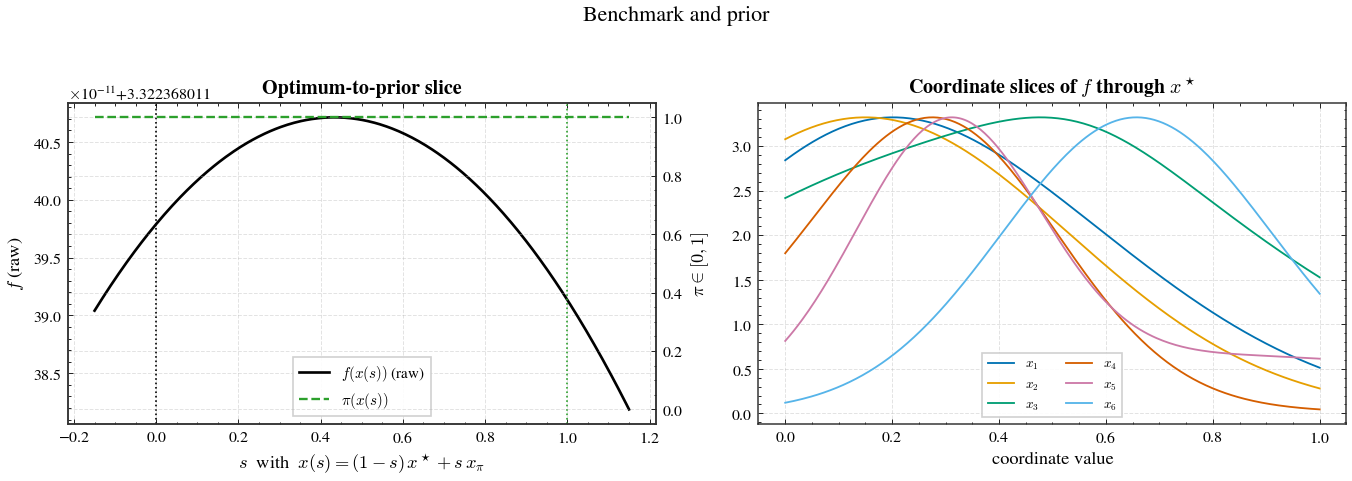

In [515]:
def grid_1d(n: int = 800) -> np.ndarray:
    return np.linspace(LB[0], UB[0], n)[:, None]

def grid_2d(n: int = 160):
    g1 = np.linspace(LB[0], UB[0], n)
    g2 = np.linspace(LB[1], UB[1], n)
    G1, G2 = np.meshgrid(g1, g2)
    XY = np.stack([G1.ravel(), G2.ravel()], axis=-1)
    return G1, G2, XY

def slice_line(n: int = 400, extend: float = 0.15):
    """Segment x(s) = (1-s) x* + s x_pi, slightly extended beyond both ends
    and clipped to the box bounds.  Returns (s, X) with X of shape (n, d)."""
    s = np.linspace(-extend, 1.0 + extend, n)
    X = (1.0 - s)[:, None] * X_STAR[None, :] + s[:, None] * X_PI[None, :]
    X = np.clip(X, LB, UB)
    return s, X

if DIM == 1:
    # The objective f is on its RAW scale; the prior pi lives in [0, 1].  They
    # are drawn on separate y-axes so neither is visually crushed by the other.
    xs = grid_1d()
    f_vals, pi_vals = _f_np(xs), _pi_np(xs)
    fig, ax = plt.subplots(figsize=(8.0, 4.2))
    axp = ax.twinx()
    lf, = ax.plot(xs[:, 0], f_vals, color="black", lw=1.6, label=r"objective $f(x)$ (raw)")
    lp, = axp.plot(xs[:, 0], pi_vals, color="#2ca02c", lw=1.4, ls="--", label=r"prior $\pi(x)$")
    mask = pi_vals >= PI_THRESHOLD
    axp.fill_between(xs[:, 0], 0, 1, where=mask, color="#2ca02c", alpha=0.08,
                     label=rf"prior region $\pi \geq {PI_THRESHOLD:g}$")
    ax.axvline(X_STAR[0], color="black", ls=":", lw=1.2)
    ls, = ax.plot(X_STAR[0], F_OPT, marker="*", ms=16, color="gold", mec="black", ls="none",
                  label=r"optimum $x^\star$", zorder=5)
    lc, = ax.plot(X_PI[0], _f_np(X_PI[None])[0], marker="v", ms=10, color="#2ca02c",
                  mec="black", ls="none", label=r"prior center $x_\pi$", zorder=5)
    li, = ax.plot(X_INIT[:, 0], _f_np(X_INIT), marker="o", ms=6, color="white", mec="black",
                  ls="none", label=f"initial design (seed {SEEDS[0]})")
    ax.set_xlabel("x"); ax.set_ylabel(r"objective $f$ (raw scale)")
    axp.set_ylabel(r"prior $\pi(x) \in [0, 1]$"); axp.set_ylim(-0.05, 1.05)
    ax.set_title("Objective and prior")
    handles = [lf, lp, ls, lc, li]
    ax.legend(handles, [h.get_label() for h in handles], loc="best", ncol=2)
    fig.tight_layout(); add_figure("01_benchmark_and_prior", fig); plt.show()

elif DIM == 2:
    G1, G2, XY = grid_2d()
    F = _f_np(XY).reshape(G1.shape)
    PI = _pi_np(XY).reshape(G1.shape)
    fig, ax = plt.subplots(figsize=(7.4, 5.6))
    im = ax.contourf(G1, G2, F, levels=30, cmap="viridis")
    fig.colorbar(im, ax=ax, label=r"$f(x)$ (raw)")
    cs = ax.contour(G1, G2, PI, levels=[0.1, PI_THRESHOLD, 0.9], colors="white",
                    linewidths=1.0, linestyles="--")
    ax.clabel(cs, fmt=lambda v: rf"$\pi$={v:g}", fontsize=8)
    ax.plot(*X_STAR, marker="*", ms=18, color="gold", mec="black", ls="none",
            label=r"$x^\star$", zorder=5)
    ax.plot(*X_PI, marker="v", ms=11, color="#2ca02c", mec="black", ls="none",
            label=r"$x_\pi$", zorder=5)
    ax.plot(X_INIT[:, 0], X_INIT[:, 1], marker="o", ms=6, color="white", mec="black",
            ls="none", label=f"initial design (seed {SEEDS[0]})")
    ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$"); ax.grid(False)
    ax.set_title("Objective and prior")
    ax.legend(loc="best")
    fig.tight_layout(); add_figure("01_benchmark_and_prior", fig); plt.show()

else:
    s, Xs = slice_line()
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
    ax = axes[0]; axp = ax.twinx()
    lf, = ax.plot(s, _f_np(Xs), color="black", lw=1.6, label=r"$f(x(s))$ (raw)")
    lp, = axp.plot(s, _pi_np(Xs), color="#2ca02c", lw=1.4, ls="--", label=r"$\pi(x(s))$")
    ax.axvline(0, color="black", ls=":", lw=1.0); ax.axvline(1, color="#2ca02c", ls=":", lw=1.0)
    ax.set_xlabel(r"$s$  with  $x(s) = (1-s)\,x^\star + s\,x_\pi$")
    ax.set_ylabel(r"$f$ (raw)"); axp.set_ylabel(r"$\pi \in [0, 1]$"); axp.set_ylim(-0.05, 1.05)
    ax.set_title("Optimum-to-prior slice")
    ax.legend([lf, lp], [lf.get_label(), lp.get_label()])
    # Coordinate-wise slices through x*.
    ax = axes[1]
    g = np.linspace(0, 1, 250)
    for j in range(DIM):
        Xj = np.repeat(X_STAR[None, :], len(g), axis=0)
        Xj[:, j] = LB[j] + g * (UB[j] - LB[j])
        ax.plot(LB[j] + g * (UB[j] - LB[j]), _f_np(Xj), lw=1.1, label=rf"$x_{{{j+1}}}$")
    ax.set_xlabel("coordinate value"); ax.set_title(r"Coordinate slices of $f$ through $x^\star$")
    ax.legend(ncol=2, fontsize=8)
    fig.suptitle("Benchmark and prior", y=1.02)
    fig.tight_layout(); add_figure("01_benchmark_and_prior", fig); plt.show()


## 2. Representative-seed qualitative analysis

All panels in this section rebuild the **exact** GP used at iteration $t$
(`state_dict` reload, no refitting) and the **exact** acquisition optimized by
each method.  Iteration $t = 1$ is the state after the initial design only.


In [516]:
REPRESENTATIVE_SEED = SEEDS[4]          # change freely
POSTERIOR_ITERS = [1, 2, 5, 6, 7, 8, 9]
POSTERIOR_ITERS = sorted({min(t, BUDGET) for t in POSTERIOR_ITERS if t >= 1})

raw_rep = load_raw(REPRESENTATIVE_SEED)
print(f"representative seed = {REPRESENTATIVE_SEED}   iterations shown = {POSTERIOR_ITERS}")


representative seed = 5   iterations shown = [1, 2, 5, 6, 7, 8, 9]


### 2.0 Sanity check — queries vs regret (full chain)

For the loaded run and the representative seed, recompute `f(x_query)` directly
from the benchmark and the regret curves from scratch, and assert they match
the stored raw values (`f_noiseless`) and the processed curves.  This rules
out raw/oriented confusion, min/max confusion, initial-design/BO
concatenation offsets, and figures built from a different run than the
regret curves.

In [517]:
# Sanity check: x_query, f(x_query), f_opt and instantaneous regret must be
# mutually consistent across raw storage, processing, and this notebook.
_sc_psd = next((p for p in PROCESSED if p.metadata.get("seed") == REPRESENTATIVE_SEED), None)
assert _sc_psd is not None, f"no processed file for seed {REPRESENTATIVE_SEED}"
print(f"benchmark = {BENCH_NAME}   prior = '{PRIOR_LABEL}'   f_opt = {F_OPT}")
for _m, _traj in raw_rep.methods.items():
    x_query  = np.asarray([s.x for s in _traj.trajectory], dtype=float)          # BO queries
    f_stored = np.asarray([s.f_noiseless for s in _traj.trajectory], dtype=float)
    f_recomp = _f_np(x_query)                                                    # f(x_query), recomputed now
    x_all = np.vstack([np.asarray(raw_rep.initial_design.X, dtype=float), x_query])
    f_all = np.concatenate(
        [np.asarray(raw_rep.initial_design.f_noiseless, dtype=float), f_recomp])
    inst_regret = F_OPT - f_all                                                  # f_opt - f(x_t)
    bsf_regret  = F_OPT - np.maximum.accumulate(f_all)                           # best-so-far regret
    proc_inst = np.asarray(_sc_psd.methods[_m].convergence.instantaneous_regret, dtype=float)
    proc_sr   = np.asarray(_sc_psd.methods[_m].convergence.simple_regret, dtype=float)
    assert np.allclose(f_recomp, f_stored, atol=1e-9), f"{_m}: stored f_noiseless != f(x_query)"
    assert np.allclose(inst_regret, proc_inst, atol=1e-9), f"{_m}: processed instantaneous regret mismatch"
    assert np.allclose(bsf_regret, proc_sr, atol=1e-9), f"{_m}: processed simple regret mismatch"
    print(f"\n[{_m}]  max|f(x_query) - f_stored| = {np.abs(f_recomp - f_stored).max():.2e}   "
          f"max|regret - processed| = {np.abs(inst_regret - proc_inst).max():.2e}")
    for _t in (0, N_INIT, min(N_INIT + 9, len(f_all) - 1), len(f_all) - 1):
        print(f"   eval {_t + 1:>3}:  x = {np.round(x_all[_t], 4).tolist()}   "
              f"f(x) = {f_all[_t]:+.4f}   inst_regret = {inst_regret[_t]:+.4f}   "
              f"best_so_far_regret = {bsf_regret[_t]:+.4f}")
print("\nOK — queries, f(x_query), f_opt and the regret curves are mutually consistent for this RUN_DIR.")

benchmark = hartmann_6d   prior = 'good'   f_opt = 3.32236801141551

[vanilla_ucb]  max|f(x_query) - f_stored| = 0.00e+00   max|regret - processed| = 0.00e+00
   eval   1:  x = [0.4803, 0.1173, 0.124, 0.3462, 0.2135, 0.5481]   f(x) = +1.7246   inst_regret = +1.5978   best_so_far_regret = +1.5978
   eval  13:  x = [0.5575, 0.0, 0.1187, 0.3757, 0.0693, 0.5542]   f(x) = +0.6100   inst_regret = +2.7123   best_so_far_regret = +1.5978
   eval  22:  x = [0.1838, 0.0, 0.1529, 0.3207, 0.3545, 0.6838]   f(x) = +2.4705   inst_regret = +0.8518   best_so_far_regret = +0.7774
   eval  92:  x = [0.2, 0.1516, 0.4768, 0.2741, 0.3132, 0.656]   f(x) = +3.3221   inst_regret = +0.0003   best_so_far_regret = +0.0001

[alpha_pi_ucb]  max|f(x_query) - f_stored| = 0.00e+00   max|regret - processed| = 0.00e+00
   eval   1:  x = [0.4803, 0.1173, 0.124, 0.3462, 0.2135, 0.5481]   f(x) = +1.7246   inst_regret = +1.5978   best_so_far_regret = +1.5978
   eval  13:  x = [0.2052, 0.1369, 0.4612, 0.2599, 0.2909, 0.6577]

### 2.1 Posterior and acquisition evolution

For each method: **top row** = true objective, posterior mean
$\mu_t \pm \sqrt{\beta}\,\sigma_t$, queried points, next query, and the prior
mean term $\hat\lambda_t\pi(x)$ (dashed) for prior-mean methods; **bottom row**
= the acquisition actually optimized (for `alpha_pi_ucb` the vanilla UCB on the
same GP is shown dashed, so the effect of the prior weighting is directly
visible).  In $d>2$ both rows are evaluated along the slice
$x(s) = (1-s)x^\star + s\,x_\pi$.


/users/eleves-b/2023/benjamin.wilhelm/gpbo-separation-of-concerns/bayesian-optimization-separation-concerns/.venv/lib64/python3.9/site-packages/gpytorch/likelihoods/noise_models.py:150: NumericalWarning: Very small noise values detected. This will likely lead to numerical instabilities. Rounding small noise values up to 1e-06.
  warnings.warn(


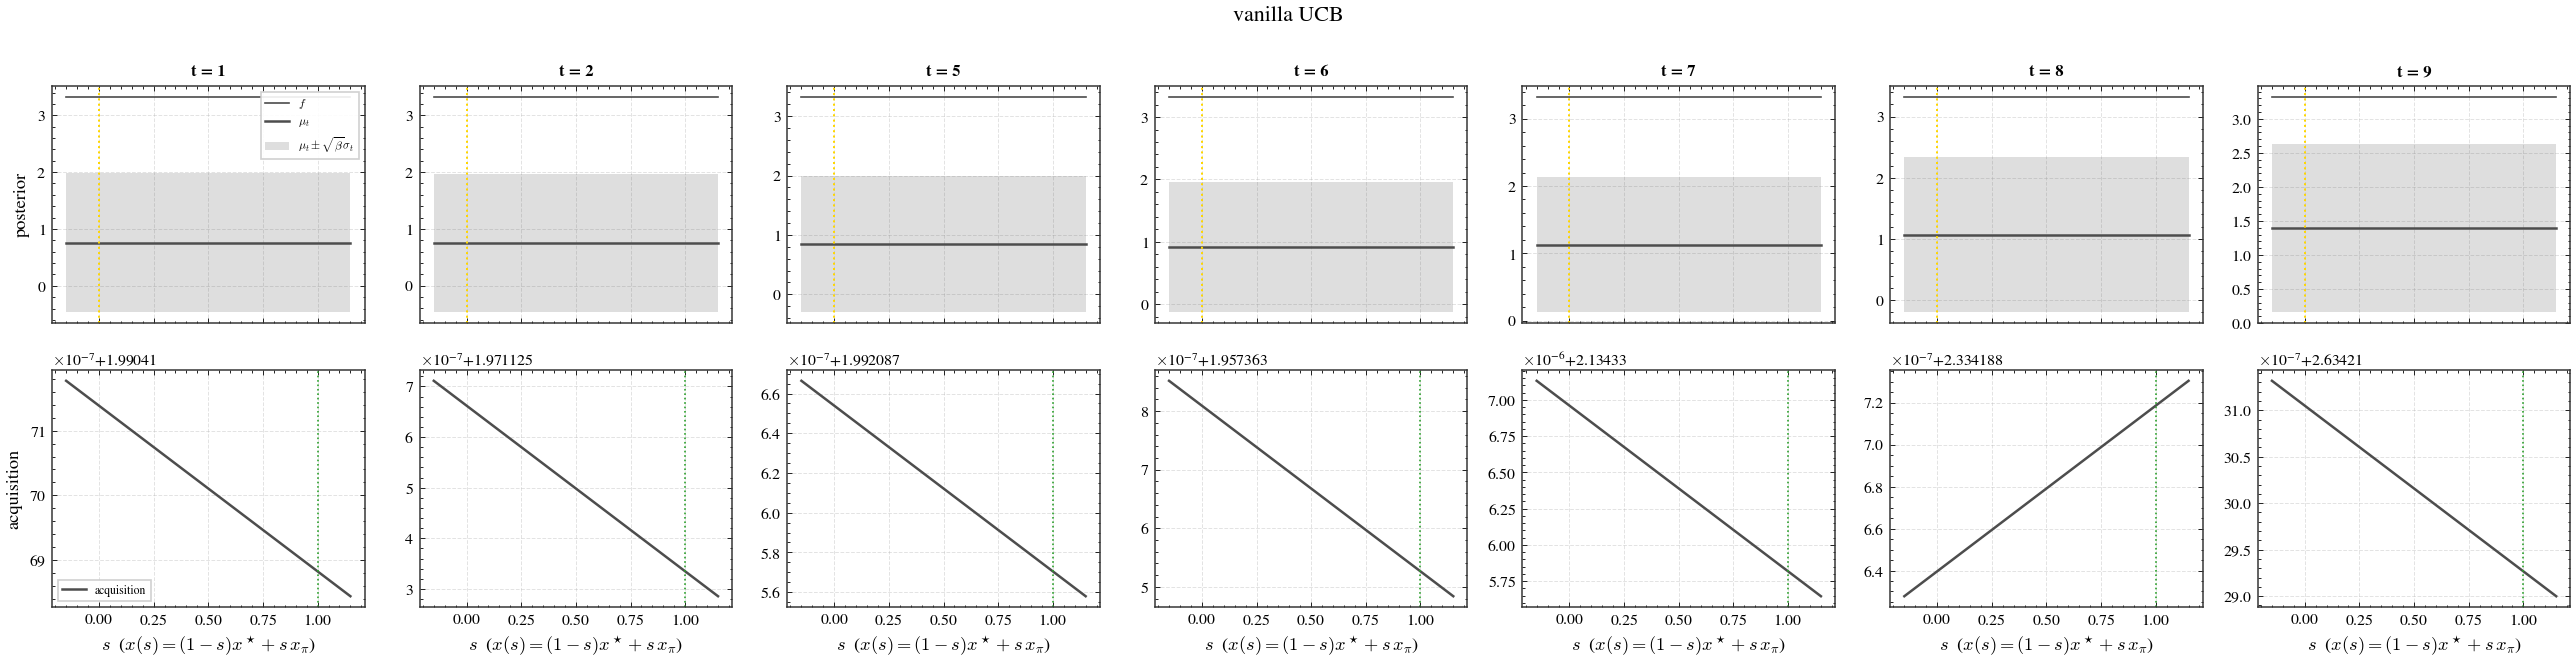

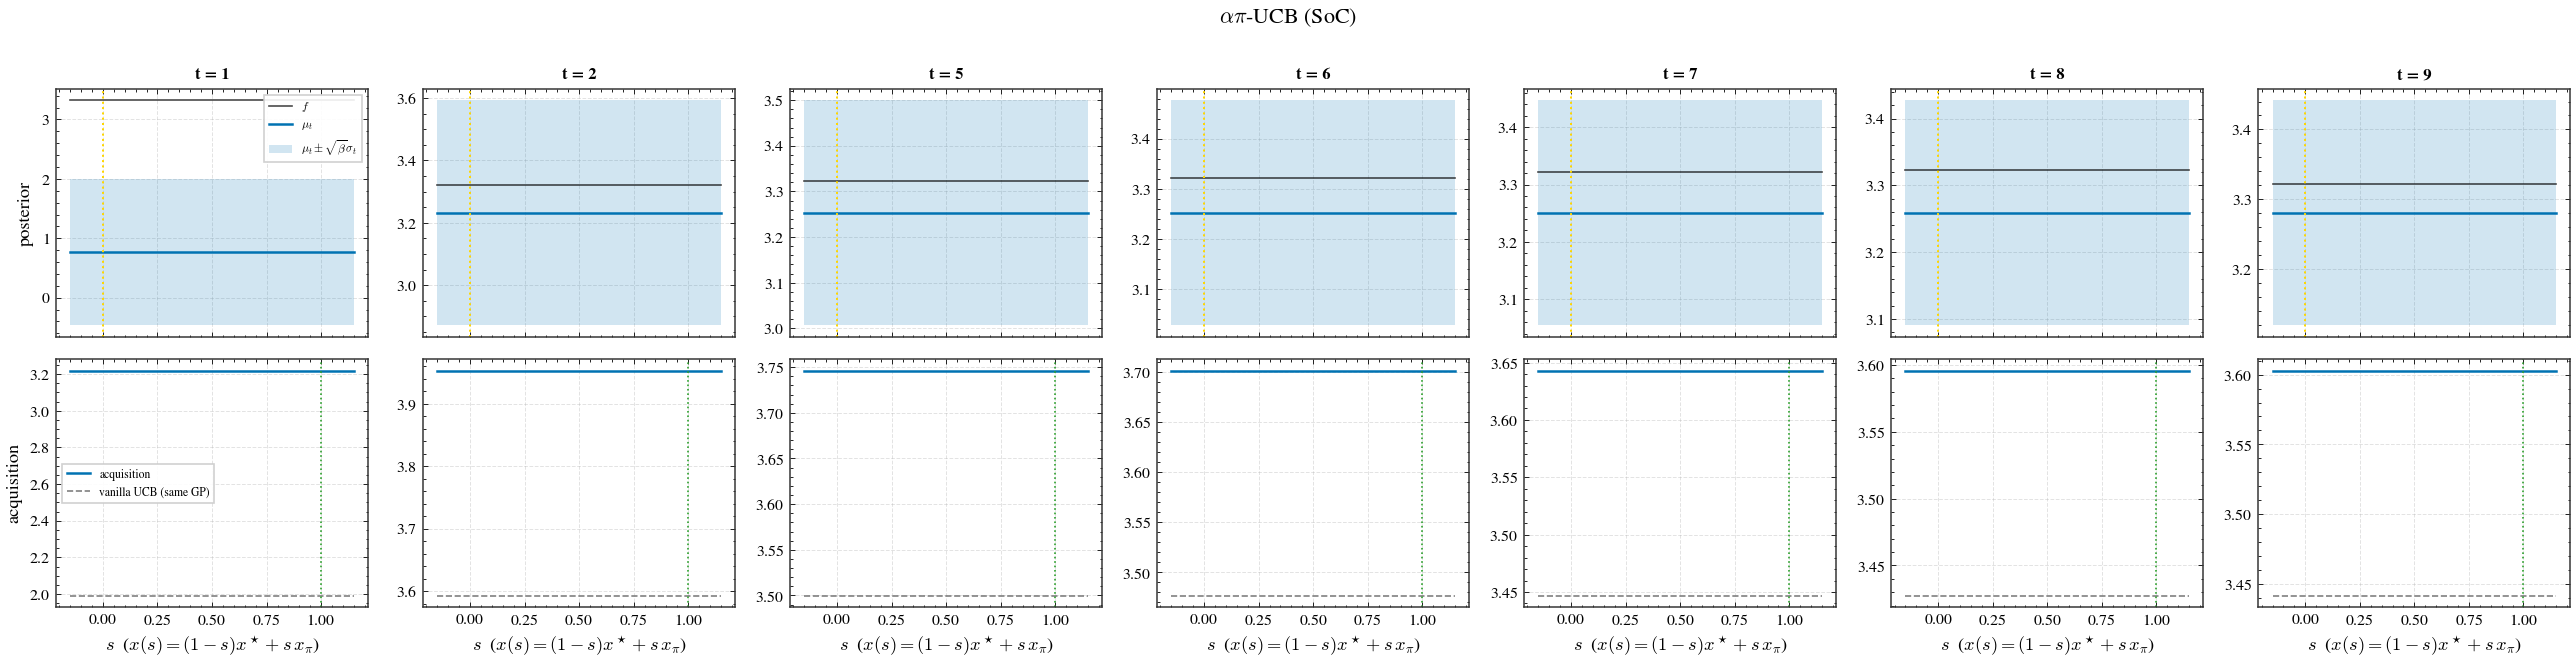

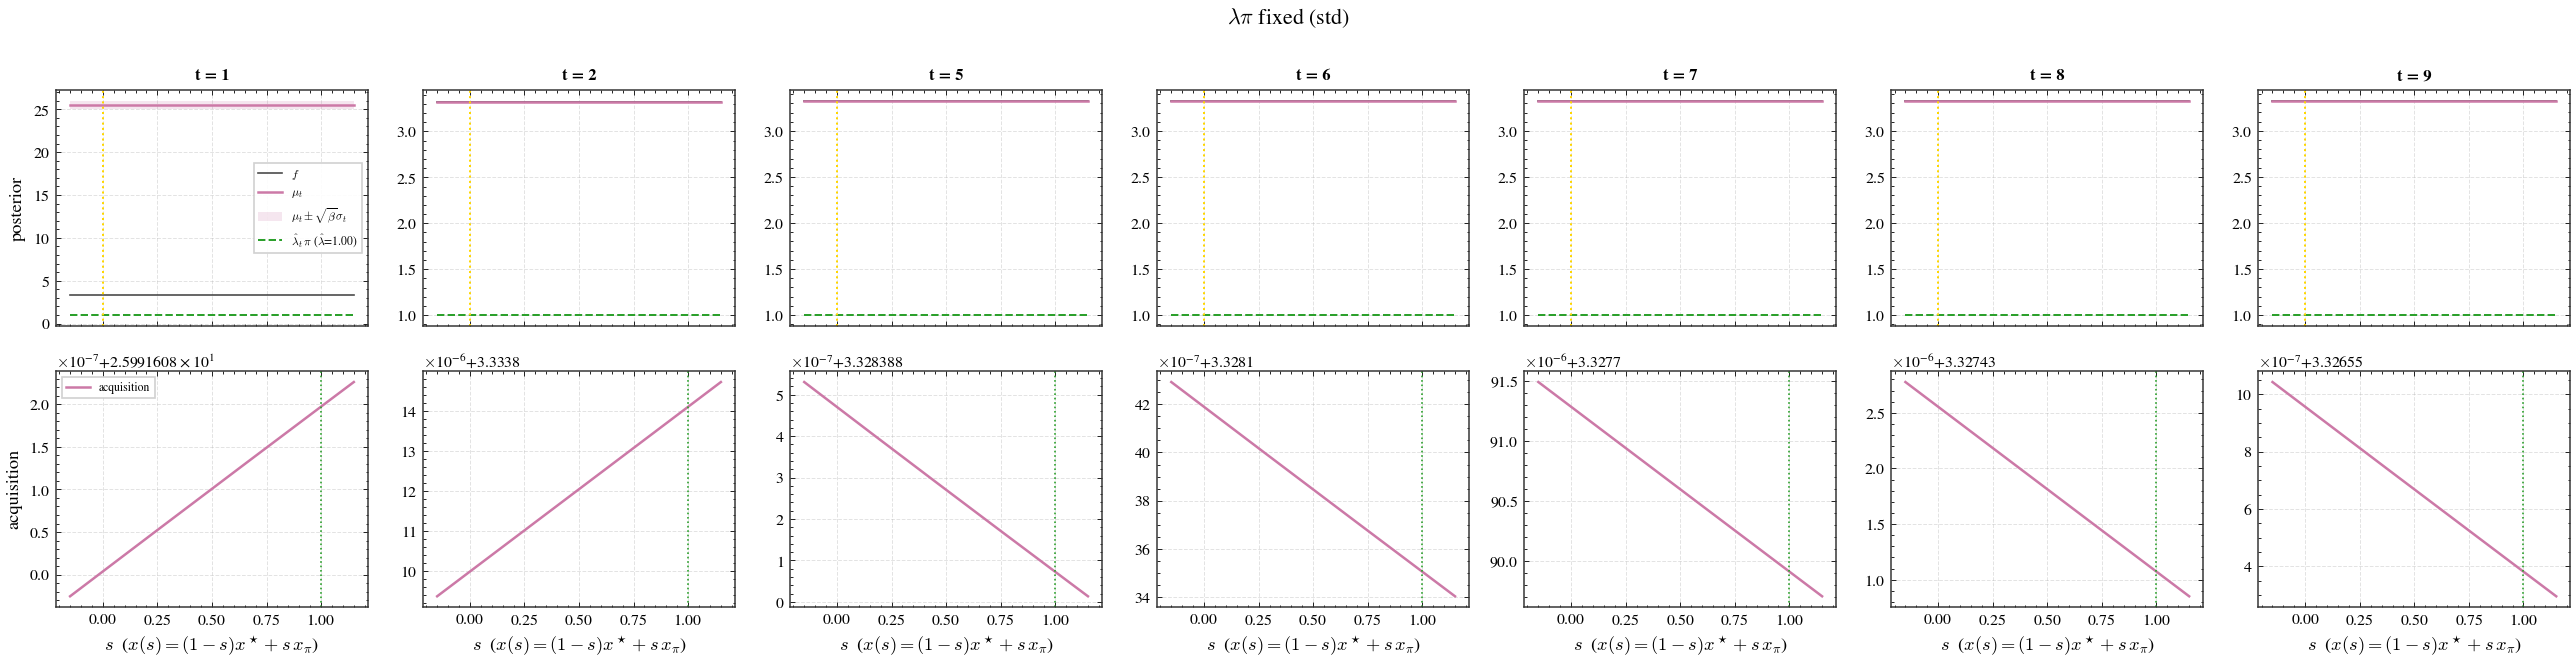

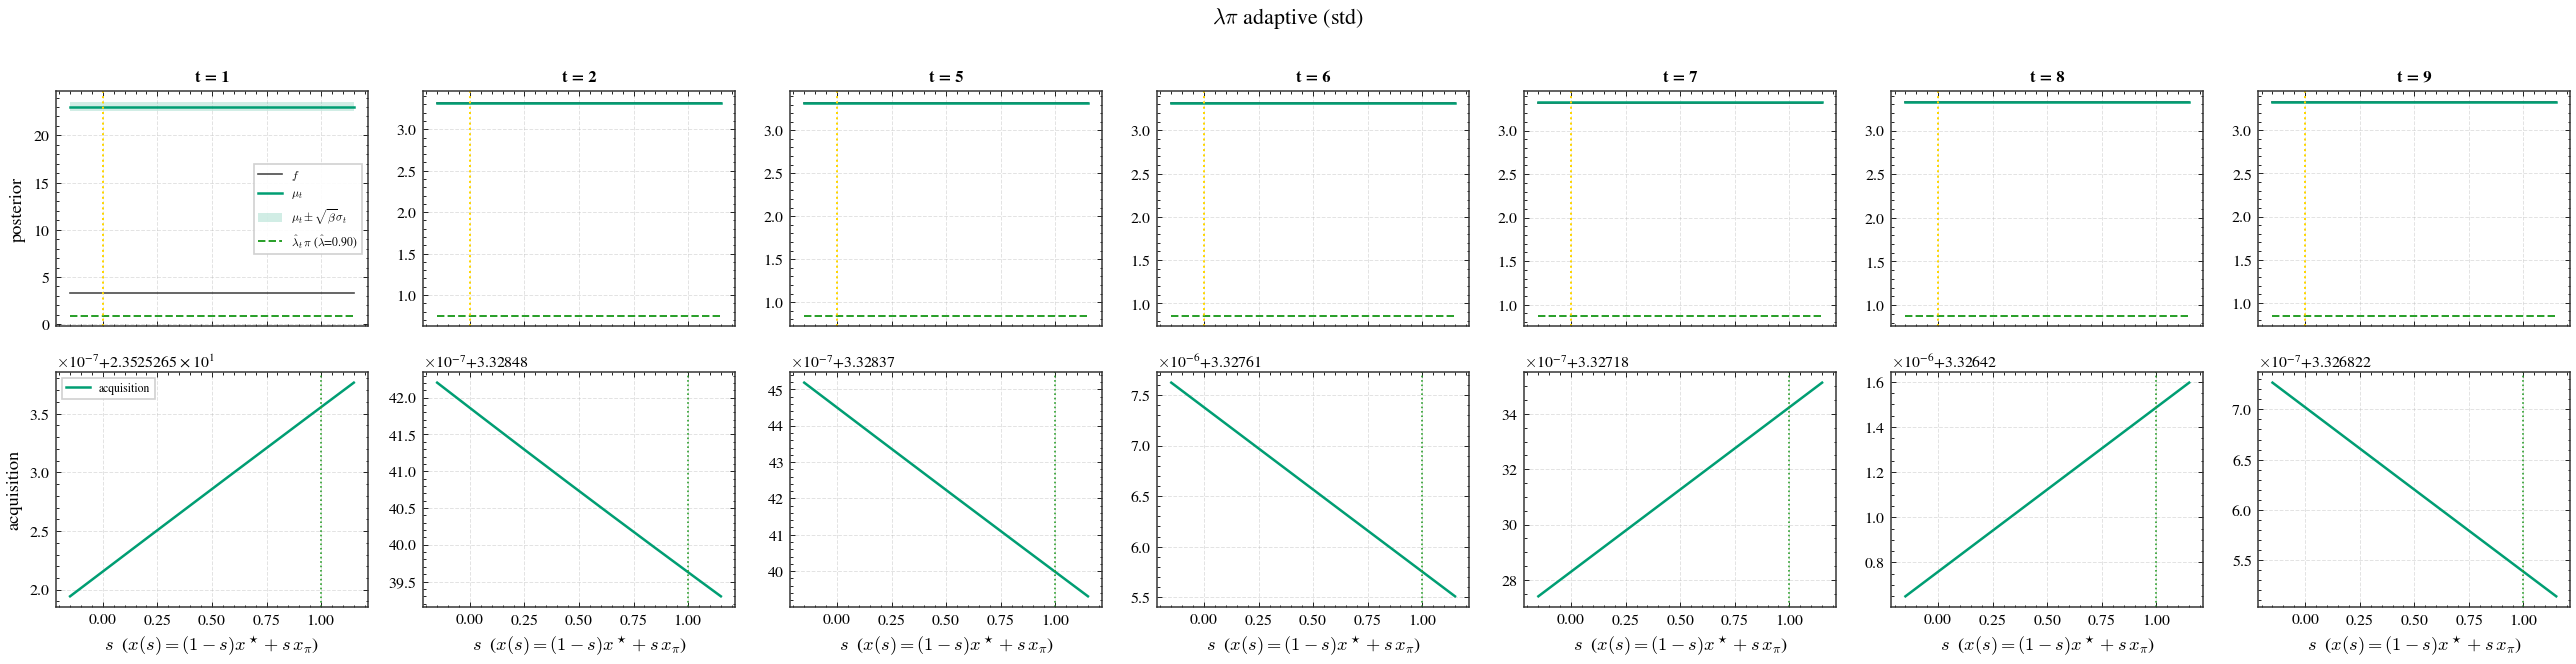

In [518]:
def _plot_posterior_acq_curves(raw, method, iters, X_eval, x_axis, x_axis_label,
                               x_star_coord, x_pi_coord, queries_proj):
    """Shared 1D / slice plotting routine (X_eval: (n, d) points to evaluate)."""
    st = style_for(method)
    f_curve = _f_np(X_eval)
    pi_curve = _pi_np(X_eval)
    n_c = len(iters)
    fig, axes = plt.subplots(2, n_c, figsize=(3.1 * n_c, 5.6),
                             sharex=True, squeeze=False)
    for k, t in enumerate(iters):
        model, train_X, snap = gp_at(raw, method, t)
        mu, sd = posterior_np(model, X_eval)
        acq = acq_for(method, model)
        a_vals = eval_acq(acq, X_eval)
        x_next = np.asarray(raw.methods[method].trajectory[t - 1].x)
        lam = lambda_at(raw, method, t)

        ax = axes[0, k]
        ax.plot(x_axis, f_curve, color="black", lw=1.0, alpha=0.7, label=r"$f$")
        ax.plot(x_axis, mu, color=st["color"], lw=1.5, label=r"$\mu_t$")
        ax.fill_between(x_axis, mu - math.sqrt(BETA) * sd, mu + math.sqrt(BETA) * sd,
                        color=st["color"], alpha=0.18, lw=0,
                        label=r"$\mu_t \pm \sqrt{\beta}\sigma_t$")
        if lam is not None:
            ax.plot(x_axis, lam * pi_curve, color="#2ca02c", ls="--", lw=1.2,
                    label=rf"$\hat\lambda_t\,\pi$ ($\hat\lambda$={lam:.2f})")
        if queries_proj is not None:
            past = queries_proj(train_X.numpy())
            ax.plot(past, _f_np(train_X.numpy()), "o", ms=4, color="white",
                    mec="black", label="queried")
        ax.axvline(x_star_coord, color="gold", ls=":", lw=1.2)
        nxt = queries_proj(x_next[None, :])[0] if queries_proj is not None else None
        if nxt is not None:
            ax.axvline(nxt, color=st["color"], ls="-", lw=0.8, alpha=0.6)
            ax.plot(nxt, _f_np(x_next[None])[0], "*", ms=13, color=st["color"],
                    mec="black", label="next query")
        ax.set_title(f"t = {t}", fontsize=10)
        if k == 0:
            ax.set_ylabel("posterior")
            ax.legend(fontsize=7, loc="best")

        ax = axes[1, k]
        ax.plot(x_axis, a_vals, color=st["color"], lw=1.5, label="acquisition")
        if method == "alpha_pi_ucb":
            ref = eval_acq(VanillaUCB(model, beta=BETA), X_eval)
            ax.plot(x_axis, ref, color="grey", ls="--", lw=1.0, label="vanilla UCB (same GP)")
        if nxt is not None:
            ax.axvline(nxt, color=st["color"], ls="-", lw=0.8, alpha=0.6)
        ax.axvline(x_pi_coord, color="#2ca02c", ls=":", lw=1.0)
        ax.set_xlabel(x_axis_label)
        if k == 0:
            ax.set_ylabel("acquisition")
            ax.legend(fontsize=7, loc="best")
    fig.suptitle(st["label"], y=1.0)
    fig.tight_layout()
    return fig

if DIM == 1:
    X_eval = grid_1d(500)
    for method in METHODS:
        fig = _plot_posterior_acq_curves(
            raw_rep, method, POSTERIOR_ITERS, X_eval, X_eval[:, 0], "x",
            X_STAR[0], X_PI[0], queries_proj=lambda X: X[:, 0])
        add_figure(f"02_posterior_acq_{method}", fig); plt.show()
elif DIM > 2:
    s, X_eval = slice_line(300)
    for method in METHODS:
        fig = _plot_posterior_acq_curves(
            raw_rep, method, POSTERIOR_ITERS, X_eval, s,
            r"$s$  ($x(s) = (1-s)x^\star + s\,x_\pi$)", 0.0, 1.0,
            queries_proj=None)
        add_figure(f"02_posterior_acq_slice_{method}", fig); plt.show()
else:
    print("d = 2: see the spatial snapshots in 2.2/2.3 instead of 1D curves.")


### 2.2 Query trajectory (spatial view, $d = 2$)

Objective heatmap, prior contours, and the query sequence colored by iteration
order (initial design in white).


In [519]:
if DIM == 2:
    G1, G2, XY = grid_2d()
    F = _f_np(XY).reshape(G1.shape)
    PI = _pi_np(XY).reshape(G1.shape)
    n_m = len(METHODS)
    ncols = 2; nrows = (n_m + 1) // 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.4 * ncols, 5.0 * nrows), squeeze=False)
    for i, method in enumerate(METHODS):
        ax = axes[i // ncols, i % ncols]
        st = style_for(method)
        ax.contourf(G1, G2, F, levels=30, cmap="viridis")
        ax.contour(G1, G2, PI, levels=[0.1, PI_THRESHOLD, 0.9], colors="white",
                   linewidths=0.8, linestyles="--")
        Q = queries_np(raw_rep, method)
        sc = ax.scatter(Q[:, 0], Q[:, 1], c=np.arange(1, len(Q) + 1), cmap="autumn",
                        s=34, edgecolors="black", linewidths=0.5, zorder=4)
        ax.plot(X_INIT[:, 0], X_INIT[:, 1], "o", ms=6, color="white", mec="black", zorder=3)
        ax.plot(*X_STAR, marker="*", ms=16, color="gold", mec="black", zorder=5)
        ax.plot(*X_PI, marker="v", ms=10, color="#2ca02c", mec="black", zorder=5)
        ax.annotate("1", Q[0], textcoords="offset points", xytext=(5, 5), color="white", fontsize=8)
        ax.annotate(str(len(Q)), Q[-1], textcoords="offset points", xytext=(5, 5),
                    color="white", fontsize=8)
        ax.set_title(st["label"]); ax.grid(False)
        ax.set_xlabel(r"$x_1$"); ax.set_ylabel(r"$x_2$")
        fig.colorbar(sc, ax=ax, label="iteration")
    for j in range(n_m, nrows * ncols):
        axes[j // ncols, j % ncols].axis("off")
    fig.suptitle("Query trajectories", y=1.0)
    fig.tight_layout(); add_figure("02_query_trajectories_2d", fig); plt.show()
else:
    print(f"d = {DIM}: spatial trajectory view only available for d = 2.")


d = 6: spatial trajectory view only available for d = 2.


### 2.3 Posterior / acquisition snapshots ($d = 2$)

For a few iterations and each method: posterior mean $\mu_t$, posterior standard
deviation $\sigma_t$, plain UCB $\mu_t + \sqrt{\beta}\sigma_t$, and the
acquisition actually optimized (they coincide except for `alpha_pi_ucb`).


In [520]:
if DIM == 2:
    SNAPSHOT_ITERS_2D = sorted({POSTERIOR_ITERS[0],
                                POSTERIOR_ITERS[len(POSTERIOR_ITERS) // 2],
                                POSTERIOR_ITERS[-1]})
    G1s, G2s, XYs = grid_2d(90)   # coarser grid: 4 posterior maps per row
    for method in METHODS:
        st = style_for(method)
        n_r = len(SNAPSHOT_ITERS_2D)
        fig, axes = plt.subplots(n_r, 4, figsize=(16.0, 3.6 * n_r), squeeze=False)
        for r, t in enumerate(SNAPSHOT_ITERS_2D):
            model, train_X, _ = gp_at(raw_rep, method, t)
            mu, sd = posterior_np(model, XYs)
            ucb = mu + math.sqrt(BETA) * sd
            a_vals = eval_acq(acq_for(method, model), XYs)
            x_next = np.asarray(raw_rep.methods[method].trajectory[t - 1].x)
            panels = [(mu, r"$\mu_t$", "viridis"), (sd, r"$\sigma_t$", "magma"),
                      (ucb, r"UCB $\mu_t+\sqrt{\beta}\sigma_t$", "cividis"),
                      (a_vals, "actual acquisition", "cividis")]
            for c, (Z, title, cmap) in enumerate(panels):
                ax = axes[r, c]
                im = ax.contourf(G1s, G2s, Z.reshape(G1s.shape), levels=25, cmap=cmap)
                fig.colorbar(im, ax=ax)
                Xq = train_X.numpy()
                ax.plot(Xq[:, 0], Xq[:, 1], "o", ms=3.5, color="white", mec="black", lw=0.4)
                ax.plot(*x_next, marker="*", ms=12, color="red", mec="black")
                ax.plot(*X_STAR, marker="*", ms=10, color="gold", mec="black")
                ax.plot(*X_PI, marker="v", ms=8, color="#2ca02c", mec="black")
                ax.set_title(f"t={t}: {title}", fontsize=10); ax.grid(False)
                ax.set_xticks([]); ax.set_yticks([])
        fig.suptitle(st["label"], y=1.0)
        fig.tight_layout(); add_figure(f"02_snapshots_2d_{method}", fig); plt.show()
else:
    print(f"d = {DIM}: 2D snapshot maps only available for d = 2.")


d = 6: 2D snapshot maps only available for d = 2.


### 2.4 Query diagnostics in high dimension ($d > 2$)

Distances of each query to the optimum and to the prior center, and a 2D PCA
projection of the queried points.  **The PCA panel is a linear projection of
the $d$-dimensional queries, not an exact representation of the search space.**


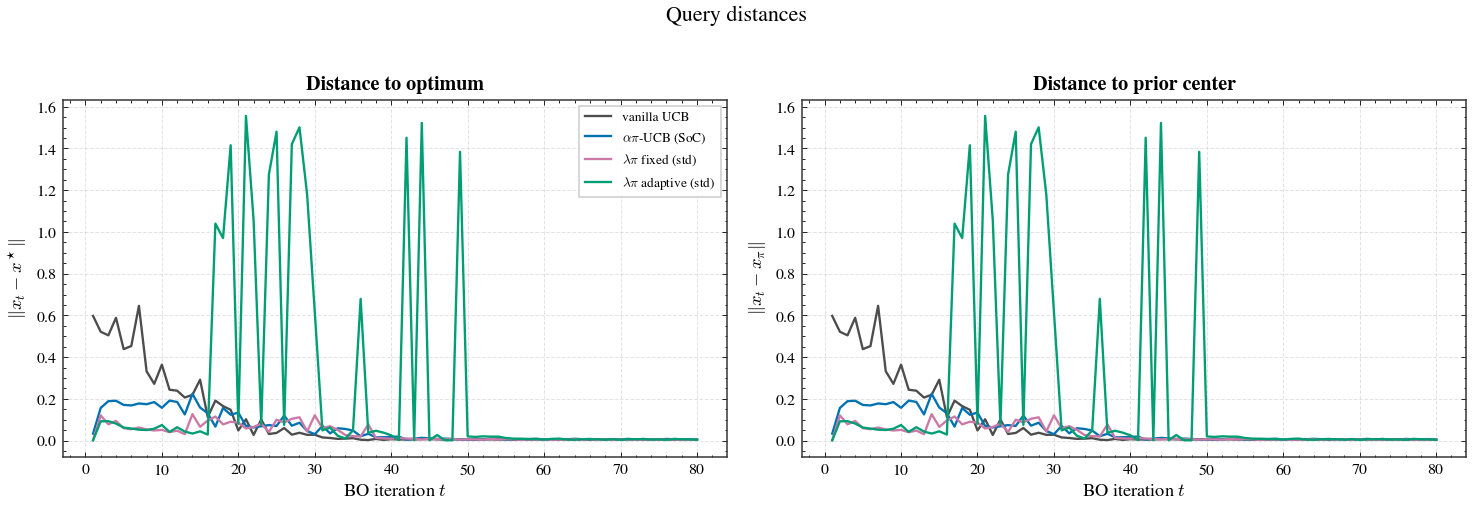

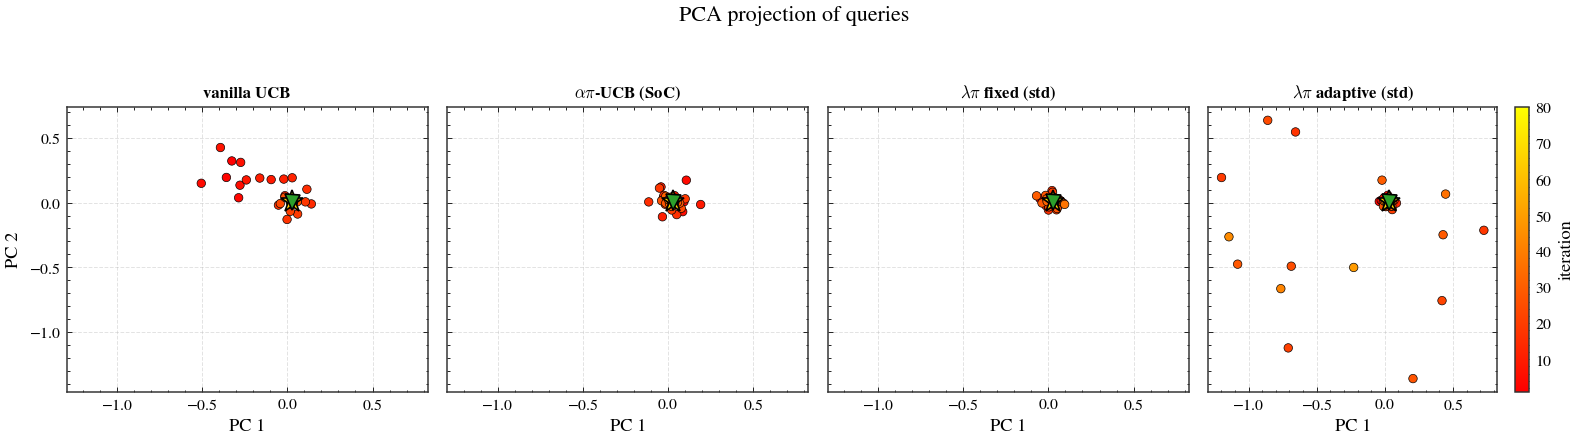

In [521]:
if DIM > 2:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
    for method in METHODS:
        st = style_for(method)
        Q = queries_np(raw_rep, method)
        t_ax = np.arange(1, len(Q) + 1)
        axes[0].plot(t_ax, np.linalg.norm(Q - X_STAR, axis=1), color=st["color"],
                     lw=1.4, label=st["label"])
        axes[1].plot(t_ax, np.linalg.norm(Q - X_PI, axis=1), color=st["color"], lw=1.4)
    axes[0].set_ylabel(r"$\Vert x_t - x^\star \Vert$"); axes[0].set_xlabel("BO iteration $t$")
    axes[0].set_title("Distance to optimum"); axes[0].legend(fontsize=8)
    axes[1].set_ylabel(r"$\Vert x_t - x_\pi \Vert$"); axes[1].set_xlabel("BO iteration $t$")
    axes[1].set_title("Distance to prior center")
    fig.suptitle("Query distances", y=1.02)
    fig.tight_layout(); add_figure("02_query_distances_seed", fig); plt.show()

    # PCA projection (fit on the pooled queries of all methods).
    pooled = np.concatenate([queries_np(raw_rep, m) for m in METHODS], axis=0)
    mu_p = pooled.mean(axis=0)
    _, _, Vt = np.linalg.svd(pooled - mu_p, full_matrices=False)
    P = Vt[:2].T                                   # (d, 2)
    fig, axes = plt.subplots(1, len(METHODS), figsize=(3.4 * len(METHODS), 3.6),
                             sharex=True, sharey=True, squeeze=False)
    for i, method in enumerate(METHODS):
        ax = axes[0, i]
        Z = (queries_np(raw_rep, method) - mu_p) @ P
        sc = ax.scatter(Z[:, 0], Z[:, 1], c=np.arange(1, len(Z) + 1), cmap="autumn",
                        s=26, edgecolors="black", linewidths=0.4)
        ax.plot(*((X_STAR - mu_p) @ P), marker="*", ms=14, color="gold", mec="black")
        ax.plot(*((X_PI - mu_p) @ P), marker="v", ms=9, color="#2ca02c", mec="black")
        ax.set_title(style_for(method)["label"], fontsize=10)
        ax.set_xlabel("PC 1")
        if i == 0:
            ax.set_ylabel("PC 2")
    fig.colorbar(sc, ax=axes[0, -1], label="iteration")
    fig.suptitle("PCA projection of queries", y=1.04)
    fig.tight_layout(); add_figure("02_query_pca_seed", fig); plt.show()
else:
    print(f"d = {DIM}: high-dimensional query diagnostics are for d > 2 "
          "(distance curves across seeds appear in section 4.3).")


## 3. Aggregate optimization performance

All curves come from `processed/aggregate/<benchmark>/convergence_curves.json`:
center = **median across seeds**, shaded area = **95% bootstrap confidence
band** of the median (band type as recorded in the file; the aggregation
convention is shared with the rest of the repository).  The iteration axis
counts the full evaluation history (initial design + BO queries); the initial
design occupies iterations $1,\dots,$ `n_init`.

Definitions (maximization on the raw scale, oracle $f(x^\star) = f_{\mathrm{opt}}$):

- **instantaneous regret** &nbsp; $r_t = f(x^\star) - f(x_t)$  *(stored key `instantaneous_regret`)*
- **best-so-far regret** &nbsp; $r_t^{\mathrm{best}} = f(x^\star) - \max_{s\le t} f(x_s)$  *(stored key `simple_regret`; relabeled here to avoid the ambiguous name)*
- **cumulative regret** &nbsp; $R_t = \sum_{s\le t} \big[f(x^\star) - f(x_s)\big]$  *(stored key `cumulative_inst_regret`)*

All three use the **noiseless** $f(x_t)$ (synthetic benchmark), never $y_{\mathrm{obs}}$.


In [522]:
CONV = AGG["convergence"]   # still used by section 4 (BO-axis curves)

# Section-3 convergence curves are built ACROSS SEEDS from the per-seed
# processed files (PROCESSED), verified in 3.0 to equal the raw JSON
# trajectories exactly.
#
# WHY NOT the bands in convergence_curves.json: that file stores the bootstrap
# CI of the median.  On a trap benchmark the median is robustly 0 (most seeds
# escape) so its CI collapses to ~0 and HIDES the runs stuck at a local
# optimum — the figure then "tends to 0" while many JSON trajectories sit at
# 0.40.  Here the shaded band is instead the INTER-SEED quantile spread (where
# the individual runs actually are), and a dashed MEAN line is overlaid: when
# the seed distribution is bimodal (escaped vs trapped) the median reads 0
# while the mean and the upper band reveal the trapped fraction.

BAND_PCT = (10, 90)     # inter-seed percentile band
_LOG_FLOOR = 1e-7       # clamp for log-scale display only

CONV_KEYS = {
    "simple_regret":            r"$r_t^{\mathrm{best}} = f(x^\star) - \max_{s\leq t} f(x_s)$",
    "instantaneous_regret":     r"$r_t = f(x^\star) - f(x_t)$",
    "cumulative_inst_regret":   r"$R_t = \sum_{s\leq t}\,[f(x^\star) - f(x_s)]$",
    "running_best_value":       r"$\max_{s\leq t} f(x_s)$",
    "prior_value_at_candidate": r"$\pi(x_t)$ (BO-iteration axis)",
    "lambda_per_iteration":     r"$\hat\lambda_t$ (BO-iteration axis)",
}
_EVAL_KEYS = {"simple_regret", "instantaneous_regret",
              "cumulative_inst_regret", "running_best_value"}

EVAL_AXIS = np.asarray(PROCESSED[0].methods[METHODS[0]].convergence.iteration, float)
BO_AXIS   = np.asarray(PROCESSED[0].methods[METHODS[0]].convergence.bo_iteration, float)

def seed_curves(method: str, key: str):
    """(n_seeds, n_steps) stack of one per-seed convergence curve, or None."""
    if key not in CONV_KEYS:
        raise KeyError(f"'{key}' is not a known curve key.  Known: {sorted(CONV_KEYS)}")
    rows = [getattr(p.methods[method].convergence, key) for p in PROCESSED
            if getattr(p.methods[method].convergence, key) is not None]
    return np.asarray(rows, dtype=float) if rows else None

def plot_conv_metric(ax, key: str, logy: bool = False):
    """Median (solid) + mean (dashed) + inter-seed band, per method."""
    x = EVAL_AXIS if key in _EVAL_KEYS else BO_AXIS
    for method in METHODS:
        A = seed_curves(method, key)
        if A is None:
            continue
        med, mean = np.median(A, 0), np.mean(A, 0)
        lo  = np.percentile(A, BAND_PCT[0], 0)
        hi  = np.percentile(A, BAND_PCT[1], 0)
        if logy:
            med, mean = np.maximum(med, _LOG_FLOOR), np.maximum(mean, _LOG_FLOOR)
            lo,  hi   = np.maximum(lo, _LOG_FLOOR),  np.maximum(hi, _LOG_FLOOR)
        st = style_for(method)
        ax.plot(x, med, color=st["color"], lw=2.4, label=st["label"])
        ax.plot(x, mean, color=st["color"], lw=1.3, ls="--", alpha=0.85)
        ax.fill_between(x, lo, hi, color=st["color"], alpha=0.14, lw=0)
    if logy:
        ax.set_yscale("log")
    ax.axvline(N_INIT + 0.5, color="grey", ls=":", lw=1.0)
    ax.set_xlabel("evaluation $t$ (initial design + BO)")
    ax.set_ylabel(CONV_KEYS[key])
    return ax

def band_caption(key: str) -> str:
    return (f"median (solid) & mean (dashed) over {len(PROCESSED)} seeds, "
            f"shaded = inter-seed {BAND_PCT[0]}–{BAND_PCT[1]} pct"
            f"\nkey: '{key}' (per-seed curves, not the bootstrap-CI aggregate)")

def conv_band(method: str, key: str):
    """Aggregate (bootstrap-CI) accessor, kept ONLY for the BO-axis curves
    still read from convergence_curves.json in section 4 (prior value, lambda)."""
    entry = (CONV or {}).get("methods", {}).get(method, {}).get(key)
    if entry is None:
        return None
    if "pointwise" in entry:
        entry = entry["pointwise"]
    return entry

if not PROCESSED:
    print("No processed per-seed files — run process.py first.")

### 3.0 Key verification

Prove the section-3 curves are faithful to the JSON trajectories: (a) each
per-seed processed curve equals its definition recomputed from the raw
`f_noiseless` history; (b) the median, mean and inter-seed percentile actually
plotted equal those recomputed directly from the raw JSON. Also report, per
method, the fraction of seeds trapped at a local optimum — the quantity the
median alone hides.

In [523]:
if not PROCESSED:
    print("processed per-seed files missing — run process.py first.")
else:
    _eval_keys = ["instantaneous_regret", "running_best_value",
                  "simple_regret", "cumulative_inst_regret"]
    _psd_rep = next(p for p in PROCESSED if p.metadata.get("seed") == REPRESENTATIVE_SEED)
    for _m in METHODS:                                  # (a) processed == definition
        _t = raw_rep.methods[_m].trajectory
        _f = np.concatenate([np.asarray(raw_rep.initial_design.f_noiseless, float),
                             _f_np(np.asarray([s.x for s in _t], float))])
        _defs = {"instantaneous_regret": F_OPT - _f,
                 "running_best_value":   np.maximum.accumulate(_f),
                 "simple_regret":        F_OPT - np.maximum.accumulate(_f),
                 "cumulative_inst_regret": np.cumsum(F_OPT - _f)}
        for _k in _eval_keys:
            _stored = np.asarray(getattr(_psd_rep.methods[_m].convergence, _k), float)
            assert np.allclose(_stored, _defs[_k], atol=1e-9), f"{_m}/{_k}: processed != definition"

    _raw_files = sorted((RUN_DIR / "raw" / BENCH_NAME).glob("seed_*.json"))
    for _m in METHODS:                                  # (b) plotted reduction == raw
        _raw = []
        for _p in _raw_files:
            _d = json.loads(_p.read_text())
            _fh = np.concatenate([
                np.asarray(_d["initial_design"]["f_noiseless"], float),
                np.asarray([s["f_noiseless"] for s in _d["methods"][_m]["trajectory"]], float)])
            _raw.append(F_OPT - np.maximum.accumulate(_fh))
        _raw = np.asarray(_raw, float)
        _plot = seed_curves(_m, "simple_regret")
        assert np.allclose(np.median(_plot, 0), np.median(_raw, 0), atol=1e-9)
        assert np.allclose(np.mean(_plot, 0),   np.mean(_raw, 0),   atol=1e-9)
        assert np.allclose(np.percentile(_plot, BAND_PCT[1], 0),
                           np.percentile(_raw, BAND_PCT[1], 0), atol=1e-9)
    print(f"OK — plotted median/mean/p{BAND_PCT[1]} match the raw JSON exactly for every method.\n")

    print(f"Final best-so-far regret across {len(PROCESSED)} seeds "
          f"(the median alone hides the trapped runs):")
    print(f"  {'method':<24}{'median':>9}{'mean':>9}{'p90':>9}{'%trapped(>0.3)':>16}")
    for _m in METHODS:
        _A = seed_curves(_m, "simple_regret")[:, -1]
        print(f"  {_m:<24}{np.median(_A):>9.3f}{np.mean(_A):>9.3f}"
              f"{np.percentile(_A, 90):>9.3f}{(_A > 0.3).mean():>15.0%}")

OK — plotted median/mean/p90 match the raw JSON exactly for every method.

Final best-so-far regret across 50 seeds (the median alone hides the trapped runs):
  method                     median     mean      p90  %trapped(>0.3)
  vanilla_ucb                 0.000    0.045    0.119             0%
  alpha_pi_ucb                0.000    0.000    0.001             0%
  lambda_pi_fixed_standardized_ucb    0.000    0.000    0.000             0%
  lambda_pi_adaptive_standardized_ucb    0.000    0.000    0.000             0%


### 3.1 Best-so-far regret (main convergence plot)

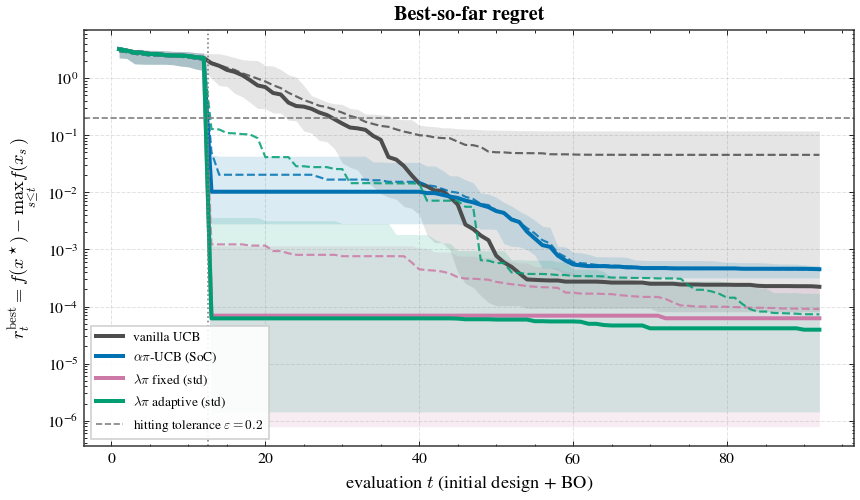

In [524]:
if PROCESSED:
    fig, ax = plt.subplots(figsize=(7.4, 4.4))
    plot_conv_metric(ax, "simple_regret", logy=True)
    if EPSILON is not None:
        ax.axhline(EPSILON, color="grey", ls="--", lw=1.0,
                   label=rf"hitting tolerance $\varepsilon = {EPSILON:g}$")
    ax.set_title("Best-so-far regret")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout(); add_figure("03_best_so_far_regret", fig); plt.show()

### 3.2 Instantaneous regret

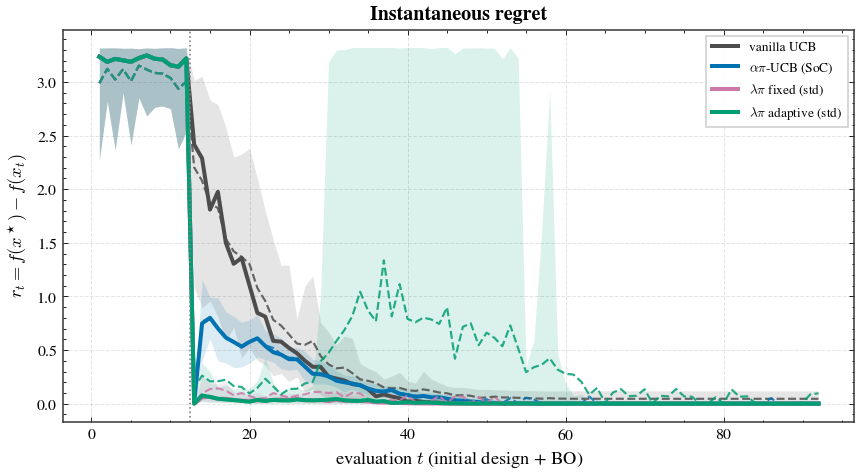

In [525]:
if PROCESSED:
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    plot_conv_metric(ax, "instantaneous_regret", logy=False)
    ax.set_title("Instantaneous regret")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout(); add_figure("03_instantaneous_regret", fig); plt.show()

### 3.3 Cumulative regret

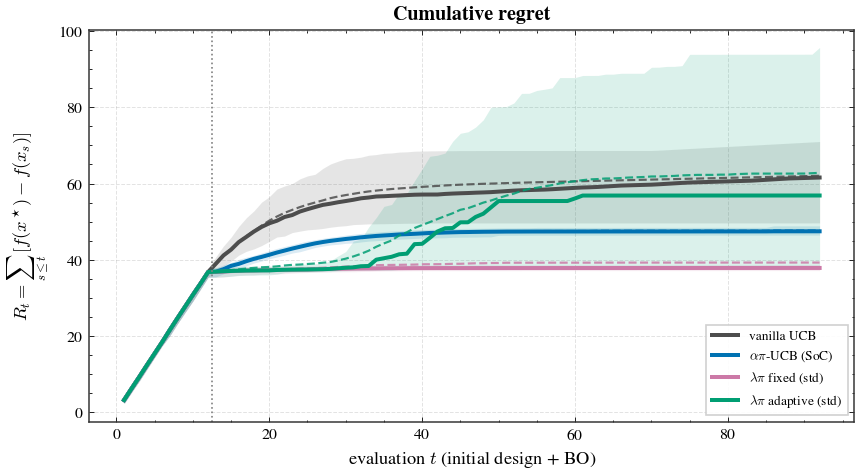

In [526]:
if PROCESSED:
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    plot_conv_metric(ax, "cumulative_inst_regret", logy=False)
    ax.set_title("Cumulative regret")
    ax.legend(loc="best", fontsize=8)
    fig.tight_layout(); add_figure("03_cumulative_regret", fig); plt.show()

### 3.4 Hitting time and failure rate

$\tau_\varepsilon = \inf\{t : r_t^{\mathrm{best}} \le \varepsilon\}$, computed by
`process.py` on the running best-so-far regret.  Runs that never reach the
tolerance within the budget carry the sentinel value `n_evaluations + 1` and are
counted as **failures** (right panel); their sentinel is excluded from the
distribution (left panel).


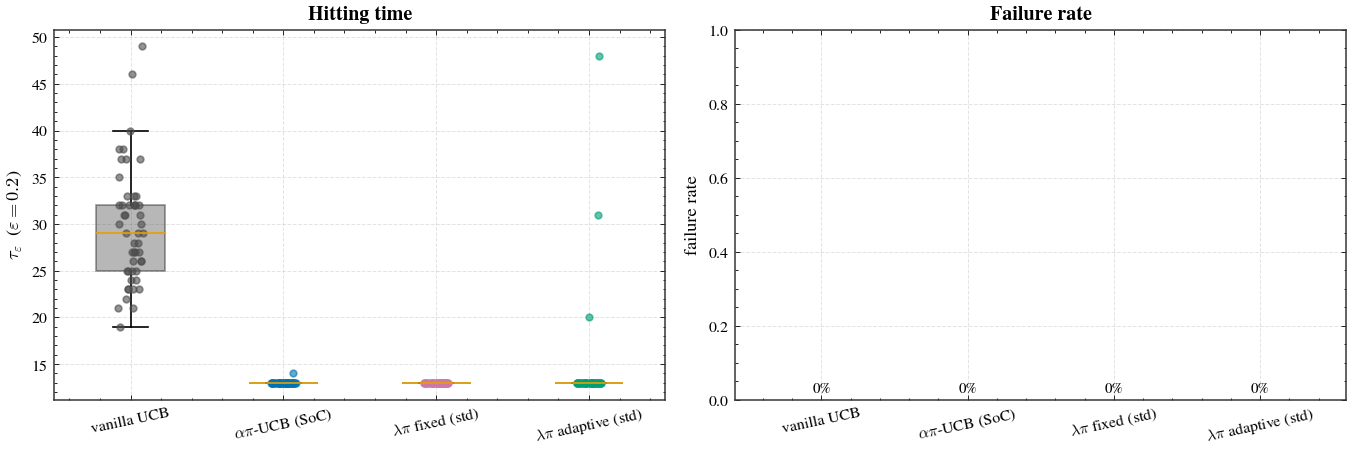

In [527]:
if EPSILON is None:
    print("No epsilon configured — hitting times were not computed.")
else:
    rows = []
    for psd in PROCESSED:
        for m in METHODS:
            ht = psd.methods[m].final.hitting_time
            if ht is not None:
                rows.append({"method": m, "seed": psd.metadata.get("seed"),
                             "hit": ht <= N_EVAL, "hitting_time": ht})
    ht_df = pd.DataFrame(rows)
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
    data, labels, colors = [], [], []
    for m in METHODS:
        sub = ht_df[(ht_df.method == m) & ht_df.hit]
        data.append(sub.hitting_time.values)
        labels.append(style_for(m)["label"]); colors.append(style_for(m)["color"])
    bp = axes[0].boxplot(data, tick_labels=labels, patch_artist=True, showfliers=False)
    for patch, c in zip(bp["boxes"], colors):
        patch.set_facecolor(c); patch.set_alpha(0.4)
    for i, d in enumerate(data):
        axes[0].plot(np.full(len(d), i + 1) + np.random.default_rng(0).uniform(-0.08, 0.08, len(d)),
                     d, "o", ms=4, color=colors[i], alpha=0.6)
    axes[0].set_ylabel(rf"$\tau_\varepsilon$  ($\varepsilon = {EPSILON:g}$)")
    axes[0].set_title("Hitting time")
    axes[0].tick_params(axis="x", rotation=12)
    fail = [1.0 - ht_df[ht_df.method == m].hit.mean() for m in METHODS]
    axes[1].bar(range(len(METHODS)), fail, color=colors, alpha=0.7,
                tick_label=labels)
    axes[1].set_ylim(0, 1.0); axes[1].set_ylabel("failure rate")
    axes[1].set_title("Failure rate")
    axes[1].tick_params(axis="x", rotation=12)
    for i, fr in enumerate(fail):
        axes[1].text(i, fr + 0.02, f"{fr:.0%}", ha="center", fontsize=9)
    fig.tight_layout(); add_figure("03_hitting_time_failure", fig); plt.show()


## 4. Mechanism diagnostics

### 4.1 Adaptive $\hat\lambda_t$ trajectory

$\hat\lambda_t$ is the prior-mean coefficient refitted by MLL at every BO
iteration (stored per seed in `convergence.lambda_per_iteration`).  Thin lines
are individual seeds; the thick line is the across-seed median with its 95%
bootstrap band.  $\hat\lambda_t \to 0$ means the model learns to **reject** the
prior; $\hat\lambda_t \approx 1$ means it keeps it.


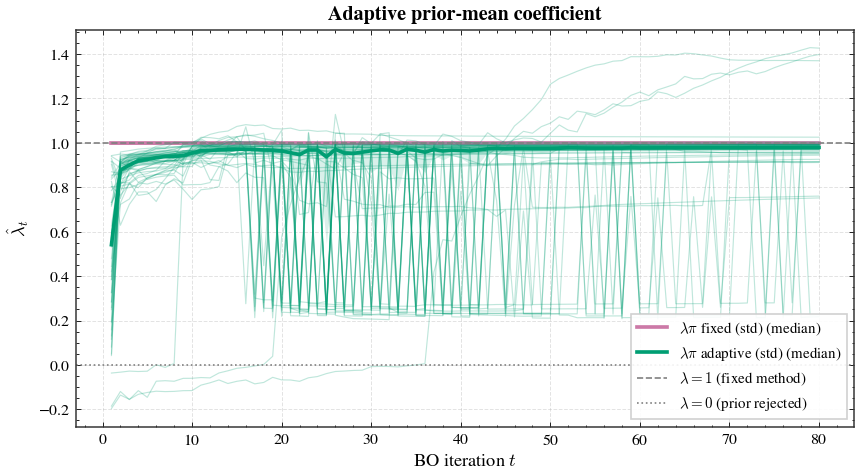

In [528]:
_lambda_methods = [m for m in METHODS
                   if any(psd.methods[m].convergence.lambda_per_iteration is not None
                          for psd in PROCESSED)]
if not _lambda_methods:
    print("No prior-mean method with stored lambda trajectories in this run.")
else:
    fig, ax = plt.subplots(figsize=(7.4, 4.2))
    bo_x = np.asarray(PROCESSED[0].methods[_lambda_methods[0]].convergence.bo_iteration, float)
    for m in _lambda_methods:
        st = style_for(m)
        for psd in PROCESSED:
            lam = psd.methods[m].convergence.lambda_per_iteration
            if lam is not None:
                ax.plot(bo_x, lam, color=st["color"], lw=0.7, alpha=0.25)
        entry = conv_band(m, "lambda_per_iteration") if CONV is not None else None
        if entry is not None:
            ax.plot(bo_x, entry["center"], color=st["color"], lw=2.2, label=st["label"] + " (median)")
            if entry.get("lower") is not None and entry["lower"][0] is not None:
                ax.fill_between(bo_x, entry["lower"], entry["upper"],
                                color=st["color"], alpha=0.15, lw=0)
    ax.axhline(1.0, color="grey", ls="--", lw=1.0, label=r"$\lambda = 1$ (fixed method)")
    ax.axhline(0.0, color="grey", ls=":", lw=1.0, label=r"$\lambda = 0$ (prior rejected)")
    ax.set_xlabel("BO iteration $t$"); ax.set_ylabel(r"$\hat\lambda_t$")
    ax.set_title("Adaptive prior-mean coefficient")
    ax.legend(loc="best")
    fig.tight_layout(); add_figure("04_lambda_trajectory", fig); plt.show()


### 4.2 Self-confirmation diagnostics for the standardized prior-mean methods

A large (or even moderate) adaptive $\hat\lambda_t$ is **not enough** to conclude
that `lambda_pi_adaptive_standardized_ucb` has genuinely *validated* the prior.
$\hat\lambda_t$ is the **generalized-least-squares (GLS) projection onto the
adaptive design $X_t$**: a biased $X_t$ can make the residual $f-\hat\lambda_t p$
small *on the queried points* while it stays large everywhere else — a
**self-confirmation loop** in which the model endorses the prior only because it
looked where the prior said to look.

**Why the old raw diagnostic no longer applies.** The earlier energy

$$
q_S(\lambda)=(f(S)-\lambda p(S))^\top C_S^{-1}(f(S)-\lambda p(S)),
\qquad C_S=K(S,S)+\sigma^2 I,
$$

is only coherent if $f$, the prior $p$, the noise and the kernel all live on **one
scale**. The methods studied here are **standardized**: the GP fits
$\tilde y=(y-m_t)/s_t$ through a `Standardize` outcome transform, and it z-scores
the prior weight, $\tilde p=(\pi-\mathrm{loc})/\mathrm{scale}$, so the learned
kernel $\tilde K$ and noise $\tilde\sigma^2$ live in **standardized coordinates**.
Mixing raw $f$ with a standardized $p$ and a standardized kernel is meaningless.
We therefore run **two separate** diagnostics on the **same standardized
trajectories $X_t$** — never mixing scales inside one quadratic form.

**Diagnostic A — internal standardized GLS residual energy (primary).** Work in
the model's own coordinates. Use the standardization $(m_t,s_t)$ **learned from
the method's observations at iteration $t$** and apply *that same* transform to
every design — the query design $X_t$, the non-adaptive Sobol references $Z_t$
(equal cardinality) and a fixed dense grid $G$ — so
$\tilde f_t(S)=(f(S)-m_t)/s_t$ and $\tilde p_t(S)$ are the model's actual view:

$$
\tilde\lambda_{X_t}=\frac{\tilde p_t(X_t)^\top \tilde C_{X_t}^{-1}\tilde f_t(X_t)}
{\tilde p_t(X_t)^\top \tilde C_{X_t}^{-1}\tilde p_t(X_t)},
\qquad
\tilde q_S^{\mathrm{res}}=\big(\tilde f_t(S)-\tilde\lambda_{X_t}\tilde p_t(S)\big)^\top
\tilde C_S^{-1}\big(\tilde f_t(S)-\tilde\lambda_{X_t}\tilde p_t(S)\big),
$$

$$
\tilde\rho_t^{\mathrm{res}}=\frac{\tilde q_{X_t}^{\mathrm{res}}}
{\operatorname{median}_Z\,\tilde q_{Z_t}^{\mathrm{res}}} .
$$

We also compare the model's **learned** $\hat\lambda_t$ with the
**GLS-reconstructed** $\tilde\lambda_{X_t}$: at the fitted kernel the mean
coefficient *is* the GLS projection, so the two should coincide (they match
exactly here because the benchmarks are noiseless, $f=y$).

**Diagnostic B — raw-scale ex-post trajectory diagnostic.** Same trajectories
$X_t$, but analysed on the **original $f$ scale**, using the raw prior
$p_{\mathrm{raw}}(x)=\text{baseline}+\text{amplitude}\cdot\pi(x)$. To keep the
model's *reconstructed* kernel we de-standardize it exactly:
$C^{\mathrm{raw}}_S=s_t^2\,\tilde C_S$ (a `Standardize` scales the covariance and
the noise by $s_t^2$). The coefficient
$\lambda^{\mathrm{raw}}_{X_t}=\big(p_{\mathrm{raw}}(X_t)^\top C^{\mathrm{raw}\,-1}_{X_t}f(X_t)\big)/
\big(p_{\mathrm{raw}}(X_t)^\top C^{\mathrm{raw}\,-1}_{X_t}p_{\mathrm{raw}}(X_t)\big)$
is **recomputed out of model** and is *not* the internal $\hat\lambda_t$; the raw
energies $q^{\mathrm{raw}}_S$ and the ratio
$\rho_t^{\mathrm{raw}}=q^{\mathrm{raw}}_{X_t}/\operatorname{median}_Z q^{\mathrm{raw}}_{Z_t}$
compare the queried points against non-adaptive references and the dense grid $G$.

**Reading the ratios.** Energies grow mechanically with $|S|$, so ratios use
**equal cardinality** ($X_t$ vs $Z_t$) and per-point normalization for the grid.
If $\rho_t\ll 1$, the residual is far smaller on the queried points than on
neutral designs — evidence of a **self-confirmation loop**. In Diagnostic B, a
small $q^{\mathrm{raw}}_{X_t}$ together with a large $q^{\mathrm{raw}}_G$ means the
standardized method queried a region where the *raw* prior only *looks*
artificially accurate.

> The standardized diagnostic measures whether the prior is locally validated in
> the internal coordinates of the fitted model. The raw-scale diagnostic is
> instead an ex-post trajectory diagnostic: it asks whether the points selected
> by the standardized method lie in a region where the raw prior appears
> artificially accurate. These are complementary diagnostics and should not be
> conflated.


In [ ]:
# Self-confirmation diagnostics for the STANDARDIZED prior-mean methods.
# Two GLS residual-energy diagnostics built from the SAME adaptive trajectories
# X_t produced by the standardized methods (see the markdown above):
#   A. internal standardized  -> the model's own (m_t, s_t)-standardized coords;
#   B. raw ex-post            -> original f scale, model kernel de-standardized
#                                (C_raw = s_t^2 * C~).  lambda_raw is OUT of model.
# Scales are never mixed inside a single quadratic form.  All linear algebra uses
# solves (not explicit inverses) with jitter for stability, and reference
# designs Z_t share the cardinality of X_t (q_S grows mechanically with |S|).
N_REF          = 12            # non-adaptive Sobol reference designs per (seed, t)
MAX_DIAG_SEEDS = min(15, len(SEEDS))
ITER_STRIDE    = 1             # subsample BO iterations if reconstruction is slow
N_GRID         = 256           # fixed dense grid G (shared across seeds/iterations)
_JIT           = 1e-8


def _is_std_prior_mean(m: str) -> bool:
    """Standardized prior-mean method (Standardize(Y) + z-scored prior weight)."""
    spec = _METHOD_SPECS.get(m, {})
    return spec.get("learn_lambda") is not None and bool(spec.get("standardize_prior_mean", False))


_diag_methods = [m for m in METHODS if _is_std_prior_mean(m)]


def _solve_quad(C: torch.Tensor, a: torch.Tensor, b: torch.Tensor) -> float:
    """a^T C^{-1} b for symmetric positive-definite C (via a linear solve)."""
    return float((a * torch.linalg.solve(C, b.unsqueeze(-1)).squeeze(-1)).sum())


def selfconf_diag_at(raw, method: str, t: int, Z_list, G_native):
    """One (seed, method, iteration): internal-standardized and raw ex-post GLS
    residual energies on the query design, references and the dense grid."""
    model, train_X, _ = gp_at(raw, method, t)
    mean = model.mean_module
    if not isinstance(mean, PriorMeanModule):
        return None
    ot = model.outcome_transform                      # Standardize learned on X_t obs.
    s_t = float(ot.stdvs.detach().flatten()[0])
    m_t = float(ot.means.detach().flatten()[0])
    if not np.isfinite(s_t) or s_t <= 0:
        return None
    var_std = float(model.likelihood.noise.detach().mean())   # standardized-space noise
    it = getattr(model, "input_transform", None)

    def _mats(S):
        """(C~, p~_std, p_raw, f_raw) for a native-coordinate design S, all in the
        model's input representation and with the LEARNED (m_t, s_t)/z-scoring."""
        St = torch.as_tensor(np.atleast_2d(S), dtype=torch.double)
        Sn = it.transform(St) if it is not None else St
        with torch.no_grad():
            K = model.covar_module(Sn).to_dense()
            p_std = mean._f_prior(Sn)                          # z-scored prior (internal)
            p_raw = mean.baseline + mean.amplitude * mean._pi(Sn)   # baseline + amp*pi
        n = K.shape[0]
        jit = _JIT * float(K.diagonal().abs().mean()) + 1e-12
        C = K + (var_std + jit) * torch.eye(n, dtype=torch.double)
        f_raw = torch.as_tensor(_f_np(np.atleast_2d(S)), dtype=torch.double)
        return C, p_std, p_raw, f_raw

    # --- query design X_t: GLS coefficients in each space ---
    Cx, px_s, px_r, frx = _mats(train_X.cpu().numpy())
    Cx_raw = s_t ** 2 * Cx
    fsx = (frx - m_t) / s_t
    d_s = _solve_quad(Cx, px_s, px_s)
    lam_s = _solve_quad(Cx, px_s, fsx) / d_s if d_s > 0 else float("nan")
    d_r = _solve_quad(Cx_raw, px_r, px_r)
    lam_r = _solve_quad(Cx_raw, px_r, frx) / d_r if d_r > 0 else float("nan")
    q_s_X = _solve_quad(Cx, fsx - lam_s * px_s, fsx - lam_s * px_s)
    q_r_X = _solve_quad(Cx_raw, frx - lam_r * px_r, frx - lam_r * px_r)
    n = frx.numel()

    # --- non-adaptive references Z_t (equal cardinality); reuse lam from X_t ---
    q_s_Z, q_r_Z = [], []
    for Z in Z_list:
        Cz, pz_s, pz_r, frz = _mats(Z)
        Cz_raw = s_t ** 2 * Cz
        fsz = (frz - m_t) / s_t
        q_s_Z.append(_solve_quad(Cz, fsz - lam_s * pz_s, fsz - lam_s * pz_s))
        q_r_Z.append(_solve_quad(Cz_raw, frz - lam_r * pz_r, frz - lam_r * pz_r))
    med_s_Z = float(np.median(q_s_Z)) if q_s_Z else float("nan")
    med_r_Z = float(np.median(q_r_Z)) if q_r_Z else float("nan")

    # --- fixed dense grid G (raw diagnostic, per-point normalized) ---
    Cg, _pg_s, pg_r, frg = _mats(G_native)
    q_r_G = _solve_quad(s_t ** 2 * Cg, frg - lam_r * pg_r, frg - lam_r * pg_r)
    ng = frg.numel()

    return dict(
        n=n, lam_std=lam_s, lam_raw=lam_r,
        rho_std=q_s_X / med_s_Z if med_s_Z > 0 else float("nan"),
        rho_raw=q_r_X / med_r_Z if med_r_Z > 0 else float("nan"),
        q_raw_X_pn=q_r_X / n, q_raw_Z_pn=med_r_Z / n, q_raw_G_pn=q_r_G / ng,
    )


if not _diag_methods:
    print("No standardized prior-mean method in this run — self-confirmation "
          "diagnostic skipped (raw lambda_pi_*_ucb methods are intentionally not used).")
else:
    from matplotlib.lines import Line2D
    _diag_seeds = SEEDS[:MAX_DIAG_SEEDS]
    _snap_iters = sorted({s.iteration for s in raw0.methods[_diag_methods[0]].model_snapshots})
    DIAG_ITERS = _snap_iters[::ITER_STRIDE]
    # Non-adaptive designs, drawn once and shared across seeds/methods so the only
    # difference between q(X_t) and q(Z_t) is WHERE the points sit.
    _G = problem.test_set(n=N_GRID, seed=2024).cpu().numpy()
    _refs = {t: [problem.test_set(n=N_INIT + (t - 1), seed=10_000 + j).cpu().numpy()
                 for j in range(N_REF)] for t in DIAG_ITERS}
    _KEYS = ("n", "lam_std", "lam_raw", "rho_std", "rho_raw",
             "q_raw_X_pn", "q_raw_Z_pn", "q_raw_G_pn")
    diag = {m: {k: np.full((len(_diag_seeds), len(DIAG_ITERS)), np.nan) for k in _KEYS}
            for m in _diag_methods}
    for si, seed in enumerate(_diag_seeds):
        rr = load_raw(seed)
        for m in _diag_methods:
            for ti, t in enumerate(DIAG_ITERS):
                try:
                    d = selfconf_diag_at(rr, m, int(t), _refs[t], _G)
                except (StopIteration, RuntimeError, ValueError):
                    d = None
                if d is None:
                    continue
                for k in _KEYS:
                    diag[m][k][si, ti] = d[k]
    print(f"standardized self-confirmation diagnostic: methods={_diag_methods}, "
          f"{len(_diag_seeds)} seeds x {len(DIAG_ITERS)} iterations, "
          f"N_REF={N_REF} references, |G|={N_GRID}.")

    tt = np.asarray(DIAG_ITERS, dtype=float)
    fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.4))
    for m in _diag_methods:
        st = style_for(m)
        D = diag[m]
        # (0,0) A - internal standardized residual ratio
        seed_band(axes[0, 0], tt, D["rho_std"], color=st["color"], label=st["label"])
        # (0,1) A - learned lambda (solid+band) vs GLS-reconstructed lambda (dashed)
        lam_model = np.asarray(
            [[(lambda_at(load_raw(s), m, int(t)) if lambda_at(load_raw(s), m, int(t)) is not None else np.nan)
              for t in DIAG_ITERS] for s in _diag_seeds], dtype=float)
        seed_band(axes[0, 1], tt, lam_model, color=st["color"], label=st["label"])
        axes[0, 1].plot(tt, np.nanmedian(D["lam_std"], axis=0), color=st["color"],
                        lw=1.4, ls="--", alpha=0.85)
        # (1,0) B - raw ex-post per-point energy: X (solid+band), Z (dashed), G (dotted)
        seed_band(axes[1, 0], tt, D["q_raw_X_pn"], color=st["color"], label=st["label"])
        axes[1, 0].plot(tt, np.nanmedian(D["q_raw_Z_pn"], axis=0), color=st["color"],
                        lw=1.3, ls="--", alpha=0.85)
        axes[1, 0].plot(tt, np.nanmedian(D["q_raw_G_pn"], axis=0), color=st["color"],
                        lw=1.3, ls=":", alpha=0.85)
        # (1,1) B - raw ex-post residual ratio
        seed_band(axes[1, 1], tt, D["rho_raw"], color=st["color"], label=st["label"])

    axes[0, 0].axhline(1.0, color="grey", ls="--", lw=1.0)
    axes[0, 0].set_yscale("log")
    axes[0, 0].set_ylabel(r"$\tilde\rho_t^{\mathrm{res}}$")
    axes[0, 0].set_title(r"A - internal standardized residual ratio")
    axes[0, 1].axhline(1.0, color="grey", ls=":", lw=1.0)
    axes[0, 1].axhline(0.0, color="grey", ls=":", lw=1.0)
    axes[0, 1].set_ylabel(r"$\lambda_t$")
    axes[0, 1].set_title(r"A - learned $\hat\lambda_t$ (solid) vs GLS $\tilde\lambda_{X_t}$ (dashed)")
    axes[1, 0].set_yscale("log")
    axes[1, 0].set_ylabel(r"$q^{\mathrm{raw}}(S)/|S|$")
    axes[1, 0].set_title(r"B - raw ex-post residual energy per point")
    axes[1, 1].axhline(1.0, color="grey", ls="--", lw=1.2)
    axes[1, 1].set_yscale("log")
    axes[1, 1].set_ylabel(r"$\rho_t^{\mathrm{raw}}$")
    axes[1, 1].set_title(r"B - raw ex-post residual ratio")

    _proxies = [Line2D([0], [0], color="grey", ls=s) for s in ("-", "--", ":")]
    axes[1, 0].legend(_proxies, [r"queried $X_t$", r"ref. median $Z_t$", r"dense grid $G$"],
                      fontsize=7, loc="best")
    for ax in (axes[0, 0], axes[0, 1], axes[1, 1]):
        ax.legend(loc="best", fontsize=8)
    for ax in axes.ravel():
        ax.set_xlabel(r"BO iteration $t$")
    fig.suptitle("Self-confirmation diagnostics (standardized prior-mean methods)", y=1.005)
    fig.tight_layout()
    add_figure("04_selfconfirmation_std", fig)
    plt.show()


### 4.3 GP hyperparameter trajectories

Read from the per-iteration `ModelSnapshot.hyperparameters` in the raw files
(no GP is rebuilt).  Lines = across-seed **median**, band = interquartile range
(this is a descriptive band, not a bootstrap CI).  For ARD kernels the
lengthscale shown is the **geometric mean over input dimensions**.  The noise
panel only appears when the noise was actually learned (it is fixed in the
default Experiment B configuration).


noise variance is fixed at 1.00e-06 — panel skipped


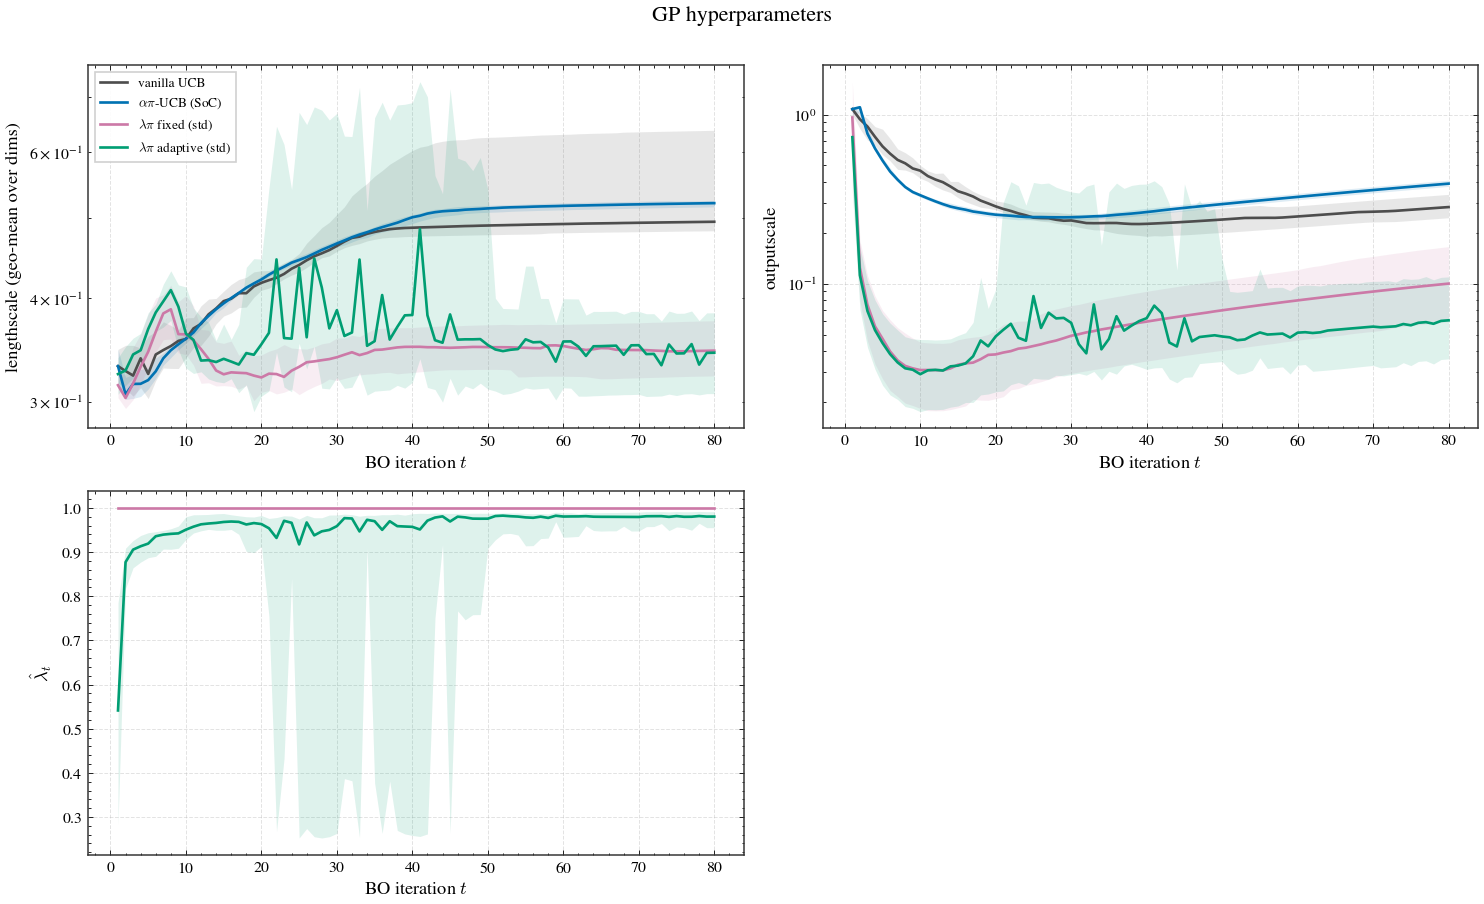

In [530]:
MAX_RAW_SEEDS = 30   # cap the number of raw files parsed for hyperparameters
_hp_seeds = SEEDS[:MAX_RAW_SEEDS]

def _hp_value(hp: dict, key: str) -> float:
    v = hp.get(key)
    if v is None:
        return np.nan
    if key == "lengthscale" and isinstance(v, list):
        arr = np.asarray(v, dtype=float).ravel()
        return float(np.exp(np.mean(np.log(np.maximum(arr, 1e-12)))))
    return float(v)

HP_KEYS = ["lengthscale", "outputscale", "noise_variance_standardized", "lambda"]
hp_data: dict[tuple, np.ndarray] = {}
for m in METHODS:
    per_key = {k: [] for k in HP_KEYS}
    for seed in _hp_seeds:
        raw = load_raw(seed)
        snaps = raw.methods[m].model_snapshots
        for k in HP_KEYS:
            per_key[k].append([_hp_value(s.hyperparameters, k) for s in snaps])
    for k in HP_KEYS:
        hp_data[(m, k)] = np.asarray(per_key[k], dtype=float)   # (n_seeds, budget)

_panels = []
for k, label in [("lengthscale", "lengthscale (geo-mean over dims)"),
                 ("outputscale", "outputscale"),
                 ("noise_variance_standardized", "noise variance"),
                 ("lambda", r"$\hat\lambda_t$")]:
    arrs = [hp_data[(m, k)] for m in METHODS]
    finite = [a for a in arrs if np.isfinite(a).any()]
    if not finite:
        continue
    if k == "noise_variance_standardized":
        allv = np.concatenate([a[np.isfinite(a)] for a in finite])
        if allv.size and np.allclose(allv, allv.flat[0]):
            print(f"noise variance is fixed at {allv.flat[0]:.2e} — panel skipped")
            continue
    _panels.append((k, label))

if _panels:
    ncols = 2; nrows = (len(_panels) + 1) // 2
    fig, axes = plt.subplots(nrows, ncols, figsize=(6.3 * ncols, 3.8 * nrows), squeeze=False)
    bo_x = np.arange(1, BUDGET + 1)
    for i, (k, label) in enumerate(_panels):
        ax = axes[i // ncols, i % ncols]
        for m in METHODS:
            A = hp_data[(m, k)]
            if not np.isfinite(A).any():
                continue
            st = style_for(m)
            med = np.nanmedian(A, axis=0)
            q25, q75 = np.nanpercentile(A, 25, axis=0), np.nanpercentile(A, 75, axis=0)
            ax.plot(bo_x, med, color=st["color"], lw=1.6, label=st["label"])
            ax.fill_between(bo_x, q25, q75, color=st["color"], alpha=0.13, lw=0)
        ax.set_xlabel("BO iteration $t$"); ax.set_ylabel(label)
        if k in ("lengthscale", "outputscale"):
            ax.set_yscale("log")
        if i == 0:
            ax.legend(fontsize=8)
    for j in range(len(_panels), nrows * ncols):
        axes[j // ncols, j % ncols].axis("off")
    fig.suptitle("GP hyperparameters", y=1.0)
    fig.tight_layout(); add_figure("04_hyperparameters", fig); plt.show()


### 4.4 Query locations: distances and prior values across seeds

Left/middle: per-iteration across-seed median (and IQR) of the distances
$\Vert x_t - x^\star\Vert$ and $\Vert x_t - x_\pi\Vert$ (raw trajectories).
Right: $\pi(x_t)$ at the selected candidates, from the aggregate
`prior_value_at_candidate` curve (median + bootstrap band) &mdash; it shows how
strongly each method samples inside the prior region.


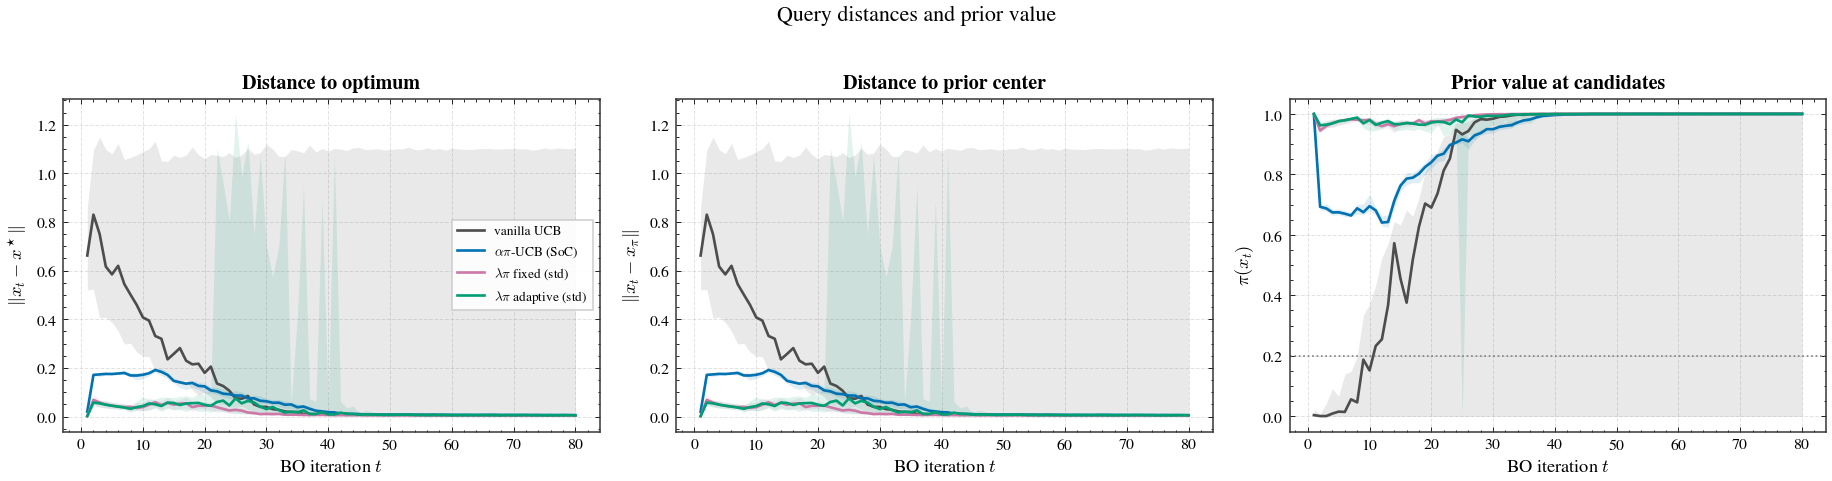

In [531]:
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
bo_x = np.arange(1, BUDGET + 1)
for m in METHODS:
    st = style_for(m)
    D_star = np.asarray([np.linalg.norm(queries_np(load_raw(s), m) - X_STAR, axis=1)
                         for s in _hp_seeds])
    D_pi = np.asarray([np.linalg.norm(queries_np(load_raw(s), m) - X_PI, axis=1)
                       for s in _hp_seeds])
    for ax, D in zip(axes[:2], (D_star, D_pi)):
        ax.plot(bo_x, np.median(D, axis=0), color=st["color"], lw=1.6, label=st["label"])
        ax.fill_between(bo_x, np.percentile(D, 25, axis=0), np.percentile(D, 75, axis=0),
                        color=st["color"], alpha=0.12, lw=0)
    entry = conv_band(m, "prior_value_at_candidate") if CONV is not None else None
    if entry is not None:
        x_bo = np.asarray(CONV["bo_iteration"], float)
        axes[2].plot(x_bo, entry["center"], color=st["color"], lw=1.6)
        if entry.get("lower") is not None and entry["lower"][0] is not None:
            axes[2].fill_between(x_bo, entry["lower"], entry["upper"],
                                 color=st["color"], alpha=0.12, lw=0)
axes[0].set_ylabel(r"$\Vert x_t - x^\star \Vert$"); axes[0].set_title("Distance to optimum")
axes[1].set_ylabel(r"$\Vert x_t - x_\pi \Vert$"); axes[1].set_title("Distance to prior center")
axes[2].set_ylabel(r"$\pi(x_t)$"); axes[2].set_title("Prior value at candidates")
axes[2].axhline(PI_THRESHOLD, color="grey", ls=":", lw=1.0)
for ax in axes:
    ax.set_xlabel("BO iteration $t$")
axes[0].legend(fontsize=8)
fig.suptitle("Query distances and prior value", y=1.02)
fig.tight_layout(); add_figure("04_query_distances", fig); plt.show()


## 5. Calibration

GP calibration is always evaluated against the **noiseless objective $f$** on a
shared held-out Sobol grid, at the GP snapshot checkpoints recorded by
`process.py`.  Reference lines: nominal 95% coverage; expected
$\beta$-band violation rate $2(1 - \Phi(\sqrt{\beta}))$; expected mean absolute
standardized residual $\sqrt{2/\pi} \approx 0.798$ under perfect calibration.

- **5.1 full grid** &mdash; the whole domain;
- **5.2 prior region** &mdash; restricted to $\{x : \pi(x) \ge \tau_\pi\}$, to
  detect overconfidence exactly where the prior pulls the search.


In [532]:
from scipy.stats import norm as _norm
_CAL = AGG["calib_curves"]
_CAL_KEYS = [("nlpd", "NLPD", None),
             ("coverage", "95% coverage", 0.95),
             ("confidence_violation_rate", r"$\beta$-band violation rate",
              float(2 * (1 - _norm.cdf(math.sqrt(BETA))))),
             ("mean_abs_standardized_residual", r"mean $|z|$", float(math.sqrt(2 / math.pi)))]

def plot_calibration_level(bucket: str, title: str, figname: str):
    if _CAL is None:
        print("calibration_curves.json missing — run analyze.py first.")
        return
    fig, axes = plt.subplots(2, 2, figsize=(12.0, 7.0), squeeze=False)
    plotted = False
    for i, (key, label, ref) in enumerate(_CAL_KEYS):
        ax = axes[i // 2, i % 2]
        for m in METHODS:
            mdat = _CAL["methods"].get(m, {})
            entry = mdat.get(bucket, {}).get(key)
            if entry is None:
                continue
            if "pointwise" in entry:
                entry = entry["pointwise"]
            x = np.asarray(mdat["iteration"], float)
            c = np.asarray(entry["center"], float)
            if not np.isfinite(c).any():
                continue
            st = style_for(m)
            ax.plot(x, c, color=st["color"], lw=1.6, marker="o", ms=3.5, label=st["label"])
            lo, up = entry.get("lower"), entry.get("upper")
            if lo is not None and up is not None and lo[0] is not None:
                ax.fill_between(x, np.asarray(lo, float), np.asarray(up, float),
                                color=st["color"], alpha=0.13, lw=0)
            plotted = True
        if ref is not None:
            ax.axhline(ref, color="grey", ls="--", lw=1.0, label=f"ideal = {ref:.3f}")
        ax.set_xlabel("BO iteration (checkpoint)"); ax.set_ylabel(label)
        if i == 0:
            ax.legend(fontsize=8)
    if plotted:
        fig.suptitle(title, y=1.0)
        fig.tight_layout(); add_figure(figname, fig); plt.show()
    else:
        plt.close(fig)
        print(f"No data for calibration bucket '{bucket}'.")


### 5.1 Full-grid calibration

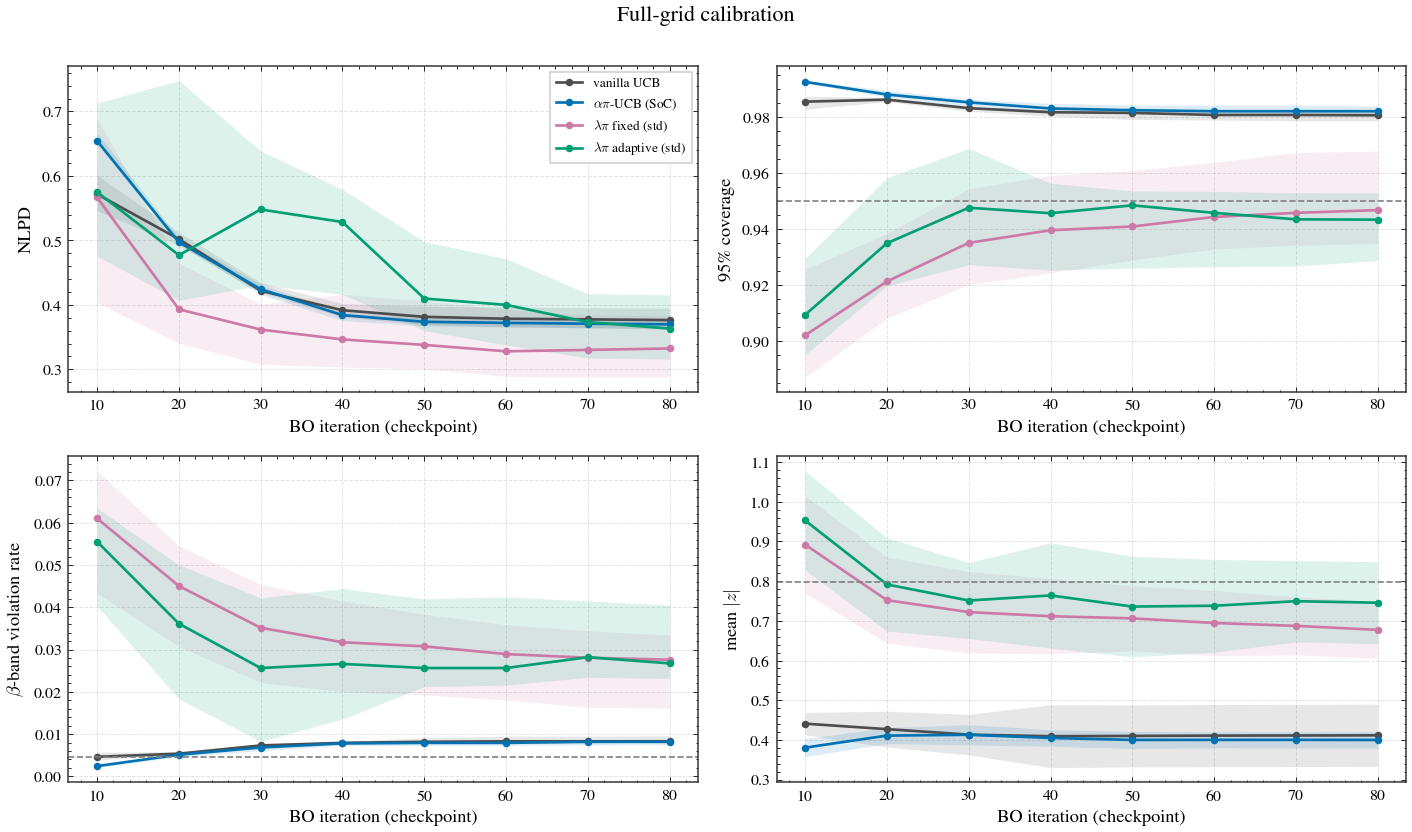

In [533]:
plot_calibration_level("global_calibration",
                       "Full-grid calibration",
                       "05_calibration_global")


### 5.2 Prior-region calibration

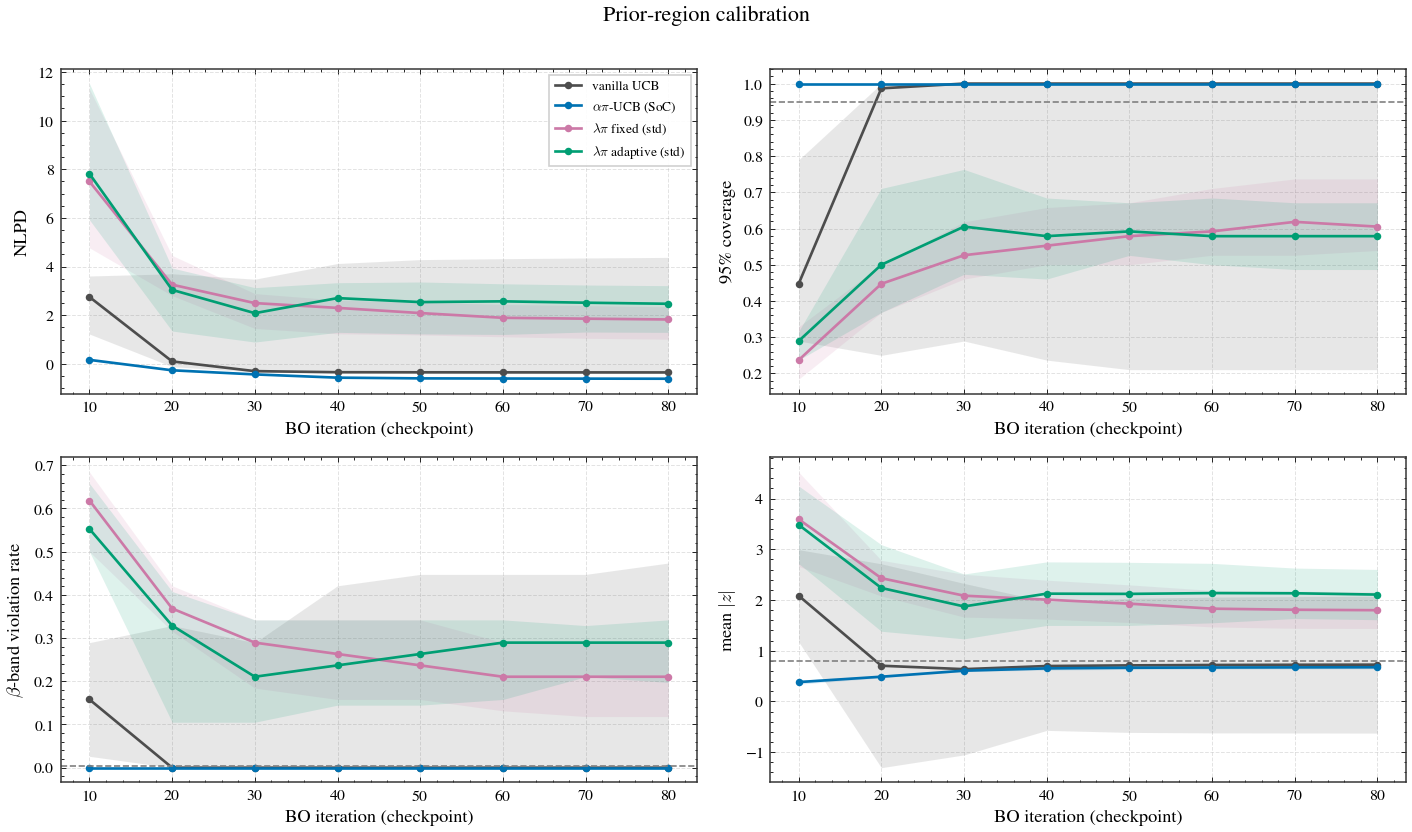

In [534]:
_n_region = PROCESSED[0].test_grid.n_prior_region if PROCESSED else None
plot_calibration_level("prior_region",
                       "Prior-region calibration",
                       "05_calibration_prior_region")


## 6. Optional detailed diagnostics

### 6.1 Final-performance summary table

Across-seed summaries (`final_performance.json`) of the headline scalars
defined in section 3 plus $\hat\lambda_T$ and the mean prior value at queries.


In [535]:
if AGG["final"] is not None:
    _keys = ["final_best_value", "final_simple_regret", "cumulative_inst_regret",
             "auc_simple_regret", "hitting_time", "lambda_final", "mean_prior_value"]
    rows = {}
    for m in METHODS:
        md_ = AGG["final"]["methods"][m]
        row = {}
        for k in _keys:
            s = md_.get(k)
            row[k] = (f"{s['median']:.4g} [{s['q25']:.4g}, {s['q75']:.4g}]"
                      if s else "—")
        rows[style_for(m)["label"]] = row
    display(pd.DataFrame(rows).T.rename_axis("method"))
    print(f"entries: median [q25, q75] over n = {AGG['final']['n_seeds']} seeds")


,final_best_value,final_simple_regret,cumulative_inst_regret,auc_simple_regret,hitting_time,lambda_final,mean_prior_value
method,,,,,,,
vanilla UCB,"3.322 [3.203, 3.322]","0.0002223 [0.0001317, 0.1194]","61.57 [56.3, 64.72]","47.83 [38.91, 53.56]","29 [25, 32]",—,"0.8213 [1.198e-06, 0.8687]"
$\alpha\pi$-UCB (SoC),"3.322 [3.322, 3.322]","0.0004515 [0.000397, 0.0004978]","47.48 [47.09, 48.1]","31.15 [25.52, 32.52]","13 [13, 13]",—,"0.9192 [0.9166, 0.9215]"
$\lambda\pi$ fixed (std),"3.322 [3.322, 3.322]","6.237e-05 [8.384e-06, 0.0001591]","37.86 [37.43, 38.46]","30.83 [24.92, 32.07]","13 [13, 13]","1 [1, 1]","0.9898 [0.9845, 0.9932]"
$\lambda\pi$ adaptive (std),"3.322 [3.322, 3.322]","3.934e-05 [1.004e-05, 0.0001307]","56.86 [38.28, 83.66]","31.16 [25.27, 32.25]","13 [13, 13]","0.9797 [0.9595, 0.9896]","0.9115 [0.8096, 0.9916]"


entries: median [q25, q75] over n = 50 seeds


### 6.2 Statistical tests vs the baseline

Paired one-sided Wilcoxon (each method vs `vanilla_ucb`, smaller-is-better
regret scalars; seeds are paired through the shared initial design), from
`statistical_tests.json`.


In [536]:
if AGG["tests"] is not None and AGG["tests"].get("comparisons"):
    rows = []
    for comp in AGG["tests"]["comparisons"]:
        for metric, entry in comp.get("metrics", {}).items():
            wil = entry.get("wilcoxon_paired") or {}
            mw = entry.get("mann_whitney") or {}
            rows.append({
                "method": style_for(comp["method"])["label"],
                "metric": metric,
                "n_paired": entry.get("n_paired"),
                "wilcoxon_p": wil.get("p_value"),
                "mann_whitney_p": mw.get("p_value"),
                "rank_biserial": entry.get("rank_biserial"),
                "cohens_d": entry.get("cohens_d_method_better"),
            })
    if rows:
        df = pd.DataFrame(rows).set_index(["method", "metric"])
        display(df.round(4))
        print(f"baseline = {AGG['tests'].get('baseline')}  "
              "(one-sided: method better than baseline)")
    else:
        print("No test entries (baseline missing from this run?).")
else:
    print("statistical_tests.json missing or empty.")


n_paired  wilcoxon_p  \
method                      metric                                         
$\alpha\pi$-UCB (SoC)       final_simple_regret           50      0.0875   
                            mean_inst_regret              50      0.0000   
                            worst_inst_regret             50         NaN   
                            cumulative_inst_regret        50      0.0000   
                            auc_simple_regret             50      0.0000   
                            hitting_time                  50      0.0000   
$\lambda\pi$ fixed (std)    final_simple_regret           50      0.0000   
                            mean_inst_regret              50      0.0000   
                            worst_inst_regret             50      0.8413   
                            cumulative_inst_regret        50      0.0000   
                            auc_simple_regret             50      0.0000   
                            hitting_time                  50      0.0000   
$\lambda\pi$ adaptive (std) final_simple_regret           50      0.0000   
                            mean_inst_regret              50      0.5646   
                            worst_inst_regret             50      1.0000   
                            cumulative_inst_regret        50      0.5646   
                            auc_simple_regret             50      0.0000   
                            hitting_time                  50      0.0000   

                                                    mann_whitney_p  \
method                      metric                                   
$\alpha\pi$-UCB (SoC)       final_simple_regret             0.9774   
                            mean_inst_regret                0.0000   
                            worst_inst_regret               0.5014   
                            cumulative_inst_regret          0.0000   
                            auc_simple_regret               0.0000   
                            hitting_time                    0.0000   
$\lambda\pi$ fixed (std)    final_simple_regret             0.0000   
                            mean_inst_regret                0.0000   
                            worst_inst_regret               0.5220   
                            cumulative_inst_regret          0.0000   
                            auc_simple_regret               0.0000   
                            hitting_time                    0.0000   
$\lambda\pi$ adaptive (std) final_simple_regret             0.0000   
                            mean_inst_regret                0.2596   
                            worst_inst_regret               1.0000   
                            cumulative_inst_regret          0.2596   
                            auc_simple_regret               0.0000   
                            hitting_time                    0.0000   

                                                    rank_biserial  cohens_d  
method                      metric                                           
$\alpha\pi$-UCB (SoC)       final_simple_regret           -0.2320    1.0890  
                            mean_inst_regret               0.9240    1.7485  
                            worst_inst_regret              0.0000    0.0000  
                            cumulative_inst_regret         0.9240    1.7485  
                            auc_simple_regret              0.8192    1.7998  
                            hitting_time                   1.0000    3.8068  
$\lambda\pi$ fixed (std)    final_simple_regret            0.6440    1.0974  
                            mean_inst_regret               0.9608    2.2025  
                            worst_inst_regret             -0.0060   -0.0030  
                            cumulative_inst_regret         0.9608    2.2025  
                            auc_simple_regret              0.8288    1.8502  
                            hitting_time                   1.0000    3.8124  
$\lambda\pi$ adaptive (std) final_simp

baseline = vanilla_ucb  (one-sided: method better than baseline)


### 6.3 Joint-posterior NLPD (full grid and prior region)

Joint Gaussian NLPD on a small subgrid (`m_test_joint_*` points), per
checkpoint.  Only available when computed by `process.py`.


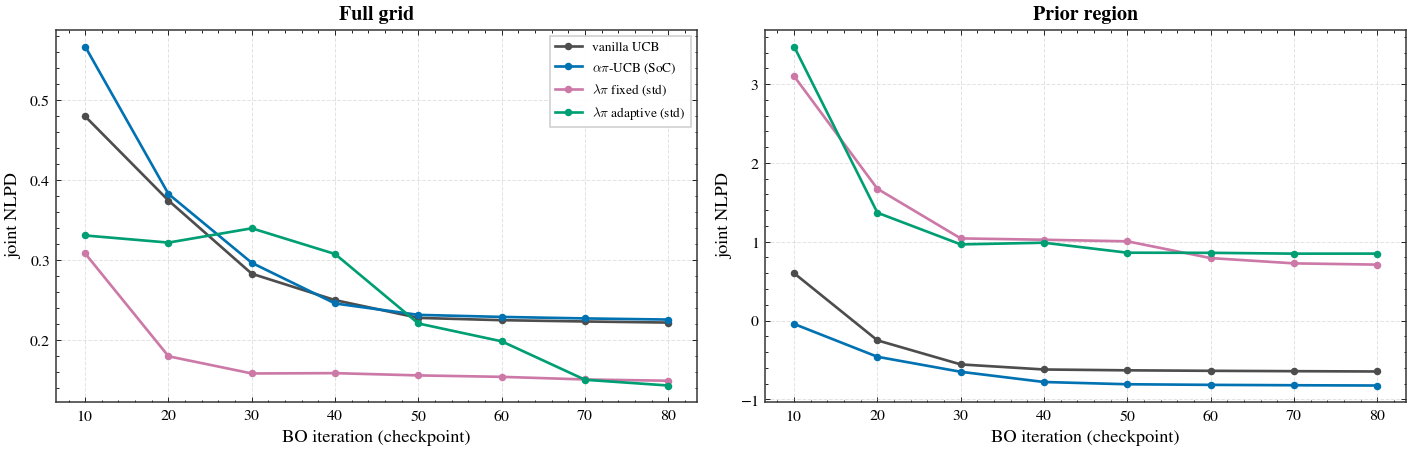

In [537]:
if _CAL is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.0))
    found = False
    for ax, (bucket, key, title) in zip(axes, [
            ("joint_posterior", "nlpd_joint", "Full grid"),
            ("prior_region", "joint_nlpd", "Prior region")]):
        for m in METHODS:
            mdat = _CAL["methods"].get(m, {})
            entry = mdat.get(bucket, {}).get(key)
            if entry is None:
                continue
            if "pointwise" in entry:
                entry = entry["pointwise"]
            c = np.asarray(entry["center"], float)
            if not np.isfinite(c).any():
                continue
            st = style_for(m)
            ax.plot(np.asarray(mdat["iteration"], float), c, color=st["color"],
                    lw=1.6, marker="o", ms=3.5, label=st["label"])
            found = True
        ax.set_xlabel("BO iteration (checkpoint)"); ax.set_ylabel("joint NLPD")
        ax.set_title(title)
    if found:
        axes[0].legend(fontsize=8)
        fig.tight_layout(); add_figure("06_joint_nlpd", fig); plt.show()
    else:
        plt.close(fig)
        print("Joint-posterior diagnostics not present in this run "
              "(set test_grid.m_test_joint_distrib / m_test_joint_prior_region).")


### 6.4 Save all registered figures

Writes every figure registered via `add_figure` to
`<run_dir>/figures/notebook/`.


In [538]:
SAVE_FIGURES = True
EXPORT_FORMATS = ("png", "pdf")   # raster for slides + vector for the report
if SAVE_FIGURES:
    out_dir = RUN_DIR / "figures" / "notebook"
    out_dir.mkdir(parents=True, exist_ok=True)
    _existing = {p.stem for p in out_dir.glob("*")
                 if p.suffix.lstrip(".").lower() in EXPORT_FORMATS}
    written = 0
    for name, fig in FIGURES.items():
        if name in _existing:
            print(f"[warn] overwriting existing figure files for '{name}'")
        for ext in EXPORT_FORMATS:
            fig.savefig(out_dir / f"{name}.{ext}")
            written += 1
    print(f"saved {len(FIGURES)} figures x {len(EXPORT_FORMATS)} formats "
          f"= {written} files to {out_dir}")
else:
    print("SAVE_FIGURES is False — nothing written.")


saved 17 figures x 2 formats = 34 files to /users/eleves-b/2023/benjamin.wilhelm/gpbo-separation-of-concerns/bayesian-optimization-separation-concerns/results/exp_b_prior_guided/runs/2026-07-02_15-25-55_hartmann_6d_good_prior/figures/notebook
